---
title: "Article 2. Reproducible manuscript Tables, Figures and Supplement"
description: |
  Publication layouts and source traceability for the current executed pipeline.
  Tables preserve full-precision numeric sources and identify their risk targets.
  Original manuscript and slides are read only. DeepSurv sensitivity is added
  only after its clean development notebooks have completed.
date: last-modified
author: "Andres Gonzalez Santa Cruz"
bibliography: [_lit/refs.bib]
csl: "_lit/american-medical-association.csl"
toc: true
toc-location: left
toc-float: true
format:
  html:
    css: [_lib/styles.scss, _lib/prediction_metrics_compact.css]
    code-fold: true
    embed-resources: true
    theme:
      - journal
    fig-cap-location: top
    toc: true
    toc-location: left
execute:
  error: false
  echo: true
  warning: true
  message: true
  freeze: auto
editor: source
execute-dir: project
lightbox: auto
---


## Publication contract
This notebook assembles executed results; it does not select models or refit them. The retained models are **b**, SHAP readmission; **e**, SHAP mortality; and **d**, Full mortality comparator. The original manuscript is the artifact inventory, not a source of replacement numbers for recalculated analyses. Pending sensitivity panels are identified explicitly until their current sources exist.
```{mermaid}
flowchart LR
 A[00: cohort and imputation] --> B[01-03: XGBoost discovery]
 B --> C[06-08: Cox comparisons]
 C --> D[09-11: frozen evaluations]
 C --> E[13: manuscript tables and figures]
 D --> E
 F[04-05 and 12: DeepSurv sensitivity] -. completed sources .-> E
```

In [1]:
#| label: publication-config-and-sources
#| message: false
.t0 <- proc.time()
# Use the existing R environment and the only project path configuration.
root<-normalizePath(getwd(),winslash="/",mustWork=TRUE)
while(!file.exists(file.path(root,"config.yml"))) {parent<-dirname(root);if(identical(parent,root))stop("config.yml not found");root<-parent}
config<-yaml::read_yaml(file.path(root,"config.yml"))
resolve<-function(x)if(grepl("^([A-Za-z]:|/)",x))x else file.path(root,x)
.libPaths(c(vapply(config$runtime$r_libraries,resolve,character(1)),.libPaths()))
Sys.setenv(OMP_NUM_THREADS="1",OPENBLAS_NUM_THREADS="1",MKL_NUM_THREADS="1")
future::plan(future::sequential)
set.seed(as.integer(config$imputation$seed))
if(.Platform$OS.type=="windows")stopifnot(nzchar(Sys.setlocale("LC_CTYPE","English_United States.utf8")))
sources<-config$publication_sources
if(any(c("eTable7_DS","eTable8_DS","eTable9_DS","Table2_DS","eFigure3_DS","eFigure4_DS")%in%names(sources))){
 ds_checkpoint<-jsonlite::read_json(file.path(resolve(config$paths$docs),"12_DeepSurv_cox_checkpoint.json"),simplifyVector=TRUE)
 stopifnot(isTRUE(ds_checkpoint$completed_comparisons),identical(ds_checkpoint$neural_endpoint,config$deepsurv$endpoint),identical(ds_checkpoint$neural_endpoint,"first_readmission_and_all_cause_death"))
 stopifnot(identical(ds_checkpoint$explanation_method,"expected_gradients_horizon_risk"),identical(ds_checkpoint$explanation_scale,"net_risk_1_minus_survival"))
}
src<-function(key){stopifnot(key%in%names(sources));p<-resolve(sources[[key]]);stopifnot(file.exists(p));p}
read_table<-function(key)utils::read.csv(src(key),stringsAsFactors=FALSE,check.names=FALSE,fileEncoding="UTF-8")
inventory<-jsonlite::read_json(src("inventory"),simplifyVector=FALSE)
items<-stats::setNames(inventory$artifacts,vapply(inventory$artifacts,`[[`,character(1),"id"))
word_sha<-digest::digest(file=resolve(config$sources$manuscript),algo="sha256")
stopifnot(identical(word_sha,inventory$manuscript_sha256))
source_hashes<-vapply(sources,function(p)digest::digest(file=resolve(p),algo="sha256"),character(1))
publication_signature<-substr(digest::digest(list(source_hashes,config$publication),algo="sha256"),1,12)
written<-character();trace<-list();packet<-list();pending<-character()
labels<-utils::read.csv(resolve(config$sources$variable_labels),stringsAsFactors=FALSE)
term_labels<-stats::setNames(labels$display_label,labels$technical_name)
term_labels[c("GLOBAL","ed_attainment_corr","prim_sub_freq_rec","eva_consumo","eva_sm","eva_fisica","eva_ocupacion","evaluacindelprocesoteraputico")]<-c("GLOBAL","Educational attainment (ordinal)","Primary-substance use frequency (ordinal)","Discharge evaluation: substance use (ordinal)","Discharge evaluation: mental health (ordinal)","Discharge evaluation: physical health (ordinal)","Discharge evaluation: occupational status (ordinal)","Discharge evaluation: therapeutic process (ordinal)")
label_term<-function(x){y<-unname(term_labels[sub("TRUE$","",x)]);y[is.na(y)]<-x[is.na(y)];y}
model_names<-c(g_readmission="g: Initial Full readmission",h_readmission="h: Full readmission without collinear term",Full_readmission="a: Full readmission, setting + discharge strata",s_readmission="SHAP readmission, setting strata",b="b: SHAP readmission, setting + discharge strata",c="c: b plus interactions",g_death="g: Initial Full mortality",h_death="h: Full mortality without collinear term",Full_mortality="d: Full mortality, setting + discharge strata",s_death="SHAP mortality, setting strata",e="e: SHAP mortality, setting + physical strata",f="f: e plus interactions",d="d: Full mortality, setting + discharge strata")
fmt<-function(x,d=3L){x[is.finite(x)&abs(x)<0.5*10^-d]<-0;formatC(x,format="f",digits=d)}
ci<-function(x,lo,hi,d=3L)paste0(fmt(x,d)," (",fmt(lo,d),", ",fmt(hi,d),")")
show_table<-function(x,title){widget<-htmltools::browsable(htmltools::tags$div(role="region",tabindex=0,`aria-label`=title,style="max-height:480px;overflow:auto;max-width:100%;",htmltools::HTML(knitr::kable(x,format="html",caption=title,row.names=FALSE,escape=TRUE))));IRdisplay::display_html(as.character(widget))}
css<-"body{font-family:Georgia,serif;color:#171717;margin:2rem;max-width:1500px}h1{font-size:1.2rem}table{border-collapse:collapse;width:100%;font-size:.85rem}th,td{padding:.38rem .5rem;text-align:left;vertical-align:top;border-bottom:1px solid #ddd}thead th{border-top:2px solid #222;border-bottom:2px solid #222;background:#eef3f4}tbody tr:nth-child(even){background:#f7f8f8}p{font-size:.85rem;line-height:1.5}.scroll{overflow:auto;max-width:100%}@media print{thead{display:table-header-group}tr{break-inside:avoid}.scroll{overflow:visible}body{margin:0}}"
export_table<-function(id,display,numeric,notes,keys,cell) {
  stopifnot(is.data.frame(display),nrow(display)>0,all(keys%in%names(sources)))
  caption<-items[[id]]$caption
  stem<-paste0(id,"_manuscript_",Sys.Date(),"_",publication_signature)
  p<-file.path(resolve(config$paths$tables),paste0(stem,".csv"));utils::write.csv(display,p,row.names=FALSE,na="")
  q<-file.path(resolve(config$paths$tables),paste0(stem,"_numeric.csv"));utils::write.csv(numeric,q,row.names=FALSE,na="")
  h<-file.path(resolve(config$paths$tables),paste0(stem,".html"))
  html<-paste0('<!doctype html><html lang="en"><meta charset="utf-8"><title>',htmltools::htmlEscape(caption),'</title><style>',css,'</style><h1>',htmltools::htmlEscape(caption),'</h1><div class="scroll">',knitr::kable(display,format="html",row.names=FALSE,escape=TRUE),'</div><p>',htmltools::htmlEscape(notes),'</p></html>')
  writeLines(html,h,useBytes=TRUE);written<<-c(written,p,q,h)
  show_table(display,caption);cat(notes,"\n")
  packet[[id]]<<-list(caption=caption,html=html,files=c(p,q,h),notes=notes)
  trace[[id]]<<-data.frame(Artifact=id,Notebook="notebooks/13_manuscript_tables_figures.ipynb",Cell=cell,Upstream_notebook=paste(vapply(items[[id]]$producers,`[[`,character(1),"notebook"),collapse="; "),Upstream_cell=paste(vapply(items[[id]]$producers,`[[`,character(1),"cell"),collapse="; "),Inputs=paste(unlist(sources[keys]),collapse="; "),Output=substring(h,nchar(root)+2L),Numeric_output=substring(q,nchar(root)+2L),Rows=nrow(numeric),Status="current executed sources")
  invisible(h)
}
show_table(data.frame(Notebook="13_manuscript_tables_figures.ipynb",Language=R.version.string,Environment="r-main / ir",Activation="Select ir; libraries in config.yml",Threads=1L),"Verified environment")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time()-.t0)["elapsed"])/60))


Notebook,Language,Environment,Activation,Threads
13_manuscript_tables_figures.ipynb,R version 4.4.1 (2024-06-14 ucrt),r-main / ir,Select ir; libraries in config.yml,1


Elapsed: 0.067 minutes


In [2]:
#| label: publication-predictor-family-labels
#| message: false
.t0 <- proc.time()
# These family/domain names follow manuscript eTables 1, 3 and 8; measured SHAP values are untouched.
family_prefix<-c(adm_age_rec3="Age at admission",sex_rec="Sex",ethnicity="Ethnicity",ed_attainment_corr="Educational attainment",occupation_condition_corr24="Occupational status",porc_pobr="Communal poverty index",cohabitation="Cohabitation status",tenure_status_household="Housing tenure",tipo_de_vivienda_rec2="Housing type",marital_status_rec="Marital status",urbanicity_cat="Urbanicity",national_foreign="Nationality",any_violence="Domestic violence/sexual abuse",first_sub_used="First substance used",primary_sub_mod="Primary substance at admission",prim_sub_freq_rec="Primary-substance use frequency",sub_dep_icd10_status="SUD severity",polysubstance_strict="Polysubstance use",dg_psiq_cie_10="Psychiatric comorbidity",dx_f="Psychiatric comorbidity",any_phys_dx="Physical comorbidity",dit_m="Treatment duration",tr_outcome="Treatment outcome",adm_motive="Admission motive",plan_type="Treatment modality",eva_consumo="Evaluation at discharge: consumption pattern",eva_sm="Evaluation at discharge: mental health",eva_fisica="Evaluation at discharge: physical health",eva_ocupacion="Evaluation at discharge: occupational situation",eva_fam="Evaluation at discharge: family",eva_relinterp="Evaluation at discharge: interpersonal relationships",eva_transgnorma="Evaluation at discharge: rule adherence",evaluacindelprocesoteraputico="Evaluation at discharge: therapeutic process")
predisposing<-c("Age at admission","Sex","Ethnicity","Educational attainment","Occupational status","Communal poverty index","Cohabitation status","Housing tenure","Housing type","Marital status","Urbanicity","Nationality","Domestic violence/sexual abuse","First substance used")
need<-c("Primary substance at admission","Primary-substance use frequency","SUD severity","Polysubstance use","Psychiatric comorbidity","Physical comorbidity")
feature_family<-function(x)vapply(x,function(v){hit<-which(startsWith(v,names(family_prefix)));stopifnot(length(hit)>0L);unname(family_prefix[hit[which.max(nchar(names(family_prefix)[hit]))]])},character(1))
feature_dimension<-function(f)ifelse(f%in%predisposing,"Predisposing",ifelse(f%in%need,"Need","Enabling & treatment-related"))
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time()-.t0)["elapsed"])/60))


Elapsed: 0.000 minutes


In [3]:
#| label: publication-table1
#| message: false
.t0 <- proc.time()
# Keep the investigator-approved first-imputation baseline table.
x<-read_table("Table1_1");x<-x[,setdiff(names(x),"Word_row")];numeric<-read_table("Table1_2")
if(identical(x$Characteristic[1],"Characteristic"))x<-x[-1,,drop=FALSE]
names(x)<-c("Characteristic","Development (n = 70,521)","Held out (n = 17,631)","SMD")
export_table("Table1",x,numeric,"Values are No. (%) unless indicated. SMD = standardized mean difference. This table uses the approved first imputation; stratum counts in eTable 14 are pooled separately across five imputations.",c("Table1_1","Table1_2"),"publication-table1")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time()-.t0)["elapsed"])/60))


Characteristic,"Development (n = 70,521)","Held out (n = 17,631)",SMD
Predisposing factors,,,
Age at admission (years),,,
Mean (SD),35.7 (10.5),35.8 (10.4),-0.008
Median [IQR],"34.2 [27.4, 42.9]","34.2 [27.5, 43.1]",
Sex (woman),"18,082 (25.6)","4,535 (25.7)",-0.002
Housing tenure,,,
Stays temporarily with a relative,"28,823 (40.9)","7,286 (41.3)",-0.009
Owner/transferred/pays dividends,"25,574 (36.3)","6,239 (35.4)",0.018
Renting,"12,744 (18.1)","3,283 (18.6)",-0.014
Illegal settlement,"1,214 (1.7)",274 (1.6),0.013


Values are No. (%) unless indicated. SMD = standardized mean difference. This table uses the approved first imputation; stratum counts in eTable 14 are pooled separately across five imputations. 


Elapsed: 0.004 minutes


In [4]:
#| label: publication-table2
#| message: false
.t0 <- proc.time()
# Assemble current formal comparisons; calibration and bootstrap have their own preserved designs.
C<-read_table("Table2_1");IBS<-read_table("Table2_3");deltaC<-read_table("Table2_2");deltaIBS<-read_table("Table2_4")
entry<-readRDS(src("Table2_5"));z<-entry$calibration_pairwise
cal<-unique(rbind(data.frame(Model=z$A,Horizon=z$Horizon,Metric=z$Metric,Value=z$Mean_A),data.frame(Model=z$B,Horizon=z$Horizon,Metric=z$Metric,Value=z$Mean_B)))
stopifnot(!anyDuplicated(cal[,c("Model","Horizon","Metric")]),all(C$Valid_B==500),all(IBS$Valid_B==500))
t2<-do.call(rbind,lapply(c("b","Full_mortality","e"),function(model)do.call(rbind,lapply(c(6,12,36,60),function(h){
 a<-C[C$Model==model&C$Horizon==h,];b<-IBS[IBS$Model==model&IBS$Horizon==h,];cc<-cal[cal$Model==model&cal$Horizon==h,];stopifnot(nrow(a)==1L,nrow(b)==1L)
 data.frame(Model=model,Horizon=h,C=a$Estimate,C_lower=a$Lower95,C_upper=a$Upper95,IBS=b$Estimate,IBS_lower=b$Lower95,IBS_upper=b$Upper95,ICI=cc$Value[cc$Metric=="ICI"],EO=cc$Value[cc$Metric=="E:O"])
}))))
x<-data.frame(Specification=unname(model_names[t2$Model]),Months=t2$Horizon,`Uno's C (95% CI)`=ci(t2$C,t2$C_lower,t2$C_upper),`IBS (95% CI)`=ci(t2$IBS,t2$IBS_lower,t2$IBS_upper),ICI=fmt(t2$ICI),`E/O`=fmt(t2$EO,2),check.names=FALSE)
# Original Table 2 direction: Full a minus b and Full d minus e; show all horizons.
for(metric in c("C","IBS")){ds<-if(metric=="C")deltaC else deltaIBS;v<-rep("",nrow(t2));for(i in which(t2$Model!="e")){A<-if(t2$Model[i]=="b")"Full_readmission" else "Full_mortality";B<-if(t2$Model[i]=="b")"b" else "e";d<-ds[ds$A==A&ds$B==B&ds$Horizon==t2$Horizon[i],];stopifnot(nrow(d)==1);v[i]<-ci(d$Delta_A_minus_B,d$Lower95,d$Upper95,if(metric=="C")4L else 6L)};x[[paste0("Delta ",metric," (95% CI)")]]<-v}
keys<-paste0("Table2_",1:5)
notes<-"C/IBS: 5 folds x 5 imputations, 500 paired patient resamples; calibration: 20 x 5 x 5. C uses horizon-specific net risk. The preserved readmission IBS uses net-survival predictions with competing-risk-aware scoring; readmission calibration uses predicted CIF and AJ observed incidence. Delta = Full a minus b, or Full d minus e; positive delta C and negative delta IBS favour Full. C censoring weights are re-estimated within each bootstrap sample; IBS contributions remain fixed by construction. New points use their own new intervals."
if("Table2_DS"%in%names(sources)){
 ds<-read_table("Table2_DS");stopifnot(nrow(ds)==8L,!anyNA(ds),all(ds$Valid_B==500L))
 labels_ds<-ifelse(ds$Outcome=="readmission","Readmission: DeepSurv-informed relaxed PH","Mortality: DeepSurv-informed relaxed PH")
 y<-data.frame(Specification=labels_ds,Months=ds$Horizon,`Uno's C (95% CI)`=ci(ds$C,ds$C_lower,ds$C_upper),`IBS (95% CI)`=ci(ds$IBS,ds$IBS_lower,ds$IBS_upper),ICI=fmt(ds$ICI),`E/O`=fmt(ds$EO,2),`Delta C (95% CI)`=ci(ds$Delta_C,ds$Delta_C_lower,ds$Delta_C_upper,4L),`Delta IBS (95% CI)`=ci(ds$Delta_IBS,ds$Delta_IBS_lower,ds$Delta_IBS_upper,6L),check.names=FALSE)
 x<-rbind(x,y);keys<-c(keys,"Table2_DS")
 for(v in setdiff(names(ds),names(t2)))t2[[v]]<-if(is.numeric(ds[[v]]))NA_real_ else NA_character_
 t2<-rbind(t2,ds[,names(t2)]);stopifnot(nrow(x)==20L,!anyNA(x))
 notes<-paste(notes,"DeepSurv-informed rows use newly selected neural models and horizon-specific expected-gradients SHAP on development-only imputations, followed by Cox fitting. Their deltas are primary reference minus sensitivity: b for readmission and Full d for mortality. These are not native-network performance estimates.")
 items$Table2$producers<-c(items$Table2$producers,list(list(notebook="notebooks/12_prediction24_converted_mod.ipynb",cell="ds-cox-etable9-and-table2-sources")))
}else notes<-paste(notes,"DeepSurv-informed blocks remain pending.")
export_table("Table2",x,t2,notes,keys,"publication-table2")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time()-.t0)["elapsed"])/60))


Specification,Months,Uno's C (95% CI),IBS (95% CI),ICI,E/O,Delta C (95% CI),Delta IBS (95% CI)
"b: SHAP readmission, setting + discharge strata",6,"0.646 (0.638, 0.653)","0.039 (0.038, 0.040)",0.007,0.99,"-0.0021 (-0.0035, -0.0007)","0.000012 (-0.000005, 0.000028)"
"b: SHAP readmission, setting + discharge strata",12,"0.633 (0.627, 0.640)","0.061 (0.060, 0.062)",0.008,0.99,"-0.0017 (-0.0032, -0.0004)","0.000022 (-0.000004, 0.000050)"
"b: SHAP readmission, setting + discharge strata",36,"0.615 (0.609, 0.619)","0.108 (0.107, 0.110)",0.009,0.99,"0.0001 (-0.0010, 0.0011)","0.000011 (-0.000050, 0.000071)"
"b: SHAP readmission, setting + discharge strata",60,"0.610 (0.605, 0.614)","0.133 (0.132, 0.135)",0.010,0.99,"-0.0001 (-0.0012, 0.0011)","-0.000009 (-0.000088, 0.000071)"
"d: Full mortality, setting + discharge strata",6,"0.783 (0.760, 0.807)","0.004 (0.004, 0.005)",0.002,1.01,"0.0159 (0.0057, 0.0267)","-0.000110 (-0.000163, -0.000055)"
"d: Full mortality, setting + discharge strata",12,"0.766 (0.746, 0.786)","0.006 (0.006, 0.007)",0.003,1.01,"0.0059 (-0.0004, 0.0124)","-0.000106 (-0.000160, -0.000052)"
"d: Full mortality, setting + discharge strata",36,"0.765 (0.752, 0.776)","0.014 (0.014, 0.015)",0.007,1.01,"-0.0003 (-0.0027, 0.0024)","-0.000076 (-0.000126, -0.000026)"
"d: Full mortality, setting + discharge strata",60,"0.763 (0.753, 0.774)","0.022 (0.021, 0.023)",0.009,1.02,"-0.0003 (-0.0023, 0.0021)","-0.000063 (-0.000120, -0.000011)"
"e: SHAP mortality, setting + physical strata",6,"0.768 (0.740, 0.791)","0.005 (0.004, 0.005)",0.002,1.01,,
"e: SHAP mortality, setting + physical strata",12,"0.760 (0.741, 0.780)","0.007 (0.006, 0.007)",0.003,1.01,,


C/IBS: 5 folds x 5 imputations, 500 paired patient resamples; calibration: 20 x 5 x 5. C uses horizon-specific net risk. The preserved readmission IBS uses net-survival predictions with competing-risk-aware scoring; readmission calibration uses predicted CIF and AJ observed incidence. Delta = Full a minus b, or Full d minus e; positive delta C and negative delta IBS favour Full. C censoring weights are re-estimated within each bootstrap sample; IBS contributions remain fixed by construction. New points use their own new intervals. DeepSurv-informed rows use newly selected neural models and horizon-specific expected-gradients SHAP on development-only imputations, followed by Cox fitting. Their deltas are primary reference minus sensitivity: b for readmission and Full d for mortality. These are not native-network performance estimates. 


Elapsed: 0.003 minutes


In [5]:
#| label: publication-table3
#| message: false
.t0 <- proc.time()
# Follow the verified per-metric arm mapping from 09 rather than relabelling all risks as CIF.
all<-read_table("Table3_1")
rows<-do.call(rbind,lapply(c("readmit","death_full","death_shap"),function(model)do.call(rbind,lapply(c(6,12,36,60),function(h){
 out<-data.frame(Model=model,Months=h)
 for(metric in c("C","IBS","IPA","ICI","EO")){arm<-if(model=="readmit")if(metric=="C")"readmit::netrisk" else "readmit::bp1_cif" else if(model=="death_full")"death::best_perf1" else "death::best_perf2";z<-all[all$arm==arm&all$horizon==h&all$metric==metric,];stopifnot(nrow(z)==1L,z$B_valid==1000L);for(v in c("estimate","lower","upper"))out[[paste(metric,v,sep="_")]]<-z[[v]]}
 out
}))))
x<-data.frame(Specification=c(readmit="Readmission b: C net risk; other columns CIF with d",death_full="Mortality d: all predictors",death_shap="Mortality e: SHAP-informed")[rows$Model],Months=rows$Months,check.names=FALSE)
for(metric in c("C","IBS","IPA","ICI","EO")){mult<-if(metric=="IPA")100 else 1;x[[paste0(metric," (95% CI)")]]<-ci(mult*rows[[paste0(metric,"_estimate")]],mult*rows[[paste0(metric,"_lower")]],mult*rows[[paste0(metric,"_upper")]],if(metric=="IPA")1L else if(metric=="EO")2L else 3L)}
export_table("Table3",x,rows,"Frozen held-out sample, n = 17,631. Five imputation predictions pooled before evaluation; 1,000 patient resamples, with models and imputers fixed. IPA is shown in percent. Readmission C uses net risk; IBS/IPA/calibration use the primary CIF with Full mortality d. Figure 3 uses its separately named CIF partner. No model was selected from these results.","Table3_1","publication-table3")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time()-.t0)["elapsed"])/60))


Specification,Months,C (95% CI),IBS (95% CI),IPA (95% CI),ICI (95% CI),EO (95% CI)
Readmission b: C net risk; other columns CIF with d,6,"0.660 (0.644, 0.675)","0.038 (0.035, 0.040)","2.4 (1.7, 3.0)","0.010 (0.008, 0.014)","1.02 (0.97, 1.08)"
Readmission b: C net risk; other columns CIF with d,12,"0.642 (0.630, 0.655)","0.059 (0.057, 0.062)","2.6 (1.9, 3.2)","0.011 (0.009, 0.016)","1.00 (0.96, 1.04)"
Readmission b: C net risk; other columns CIF with d,36,"0.626 (0.616, 0.636)","0.106 (0.103, 0.109)","3.2 (2.6, 3.8)","0.016 (0.012, 0.022)","0.99 (0.96, 1.03)"
Readmission b: C net risk; other columns CIF with d,60,"0.621 (0.612, 0.630)","0.132 (0.128, 0.135)","3.0 (2.4, 3.6)","0.019 (0.014, 0.026)","0.97 (0.94, 1.00)"
Mortality d: all predictors,6,"0.806 (0.760, 0.846)","0.004 (0.003, 0.005)","4.7 (1.7, 7.8)","0.002 (0.002, 0.003)","1.18 (1.00, 1.46)"
Mortality d: all predictors,12,"0.789 (0.753, 0.820)","0.005 (0.005, 0.006)","3.5 (1.1, 6.0)","0.002 (0.002, 0.004)","1.17 (1.02, 1.39)"
Mortality d: all predictors,36,"0.782 (0.759, 0.805)","0.013 (0.012, 0.015)","3.9 (2.5, 5.3)","0.007 (0.006, 0.010)","1.02 (0.93, 1.12)"
Mortality d: all predictors,60,"0.754 (0.730, 0.776)","0.021 (0.019, 0.023)","5.2 (3.9, 6.5)","0.009 (0.008, 0.012)","1.07 (1.00, 1.15)"
Mortality e: SHAP-informed,6,"0.786 (0.737, 0.828)","0.004 (0.003, 0.005)","1.2 (0.2, 2.1)","0.002 (0.002, 0.003)","1.17 (0.98, 1.46)"
Mortality e: SHAP-informed,12,"0.776 (0.739, 0.808)","0.006 (0.005, 0.007)","1.2 (0.1, 2.2)","0.002 (0.002, 0.004)","1.16 (1.01, 1.37)"


Frozen held-out sample, n = 17,631. Five imputation predictions pooled before evaluation; 1,000 patient resamples, with models and imputers fixed. IPA is shown in percent. Readmission C uses net risk; IBS/IPA/calibration use the primary CIF with Full mortality d. Figure 3 uses its separately named CIF partner. No model was selected from these results. 


Elapsed: 0.004 minutes


In [6]:
#| label: publication-table4
#| message: false
.t0 <- proc.time()
# Preserve each additional cohort and the exact completed patient-bootstrap intervals.
a<-read_table("Table4_1");b<-read_table("Table4_C3")
rows<-do.call(rbind,lapply(seq_len(nrow(a)),function(i){z<-a[i,];do.call(rbind,lapply(c(C="uno_c",IBS="ibs",ICI="ici",EO="expected_to_observed"),function(m)data.frame(Cohort="Temporal readmission, 2021-2024",Horizon=z$horizon_months,Metric=names(c(C="uno_c",IBS="ibs",ICI="ici",EO="expected_to_observed"))[match(m,c("uno_c","ibs","ici","expected_to_observed"))],Value=z[[m]],Lower=z[[paste0(m,"_lower_95")]],Upper=z[[paste0(m,"_upper_95")]])))}))
rows<-rbind(rows,data.frame(Cohort="Homelessness programme mortality, primary n = 613",b[,c("Horizon","Metric","Value","Lower","Upper")]))
x<-do.call(rbind,lapply(split(rows,list(rows$Cohort,rows$Horizon),drop=TRUE),function(z){r<-data.frame(Subsample=z$Cohort[1],Months=z$Horizon[1]);for(m in c("C","IBS","ICI","EO")){q<-z[z$Metric==m,];stopifnot(nrow(q)==1);r[[paste0(m," (95% CI)")]]<-ci(q$Value,q$Lower,q$Upper,if(m=="EO")2L else 3L)};r}))
x<-x[order(grepl("Homeless",x$Subsample),x$Months),]
export_table("Table4",x,rows,"Additional evaluations within SENDA. Temporal: 24,014 people, net-risk arm, follow-up closes 20 December 2024. Homelessness programme: 613 people and 72 deaths; five missing discharge reasons excluded only from this primary analysis. The separate 618-person sensitivity is exported below. The trained poverty definition is retained; its source-year issue was not corrected or isolated. Percentile 95% intervals use 1,000 resamples.",c("Table4_1","Table4_C3"),"publication-table4")
sensitivity<-read_table("Table4_C3_sensitivity");show_table(sensitivity,"Table 4 supporting sensitivity: 618 people; actual donor uncertainty")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time()-.t0)["elapsed"])/60))


Subsample,Months,C (95% CI),IBS (95% CI),ICI (95% CI),EO (95% CI)
"Temporal readmission, 2021-2024",6,"0.703 (0.687, 0.719)","0.028 (0.026, 0.029)","0.014 (0.012, 0.018)","1.25 (1.18, 1.31)"
"Temporal readmission, 2021-2024",12,"0.667 (0.655, 0.680)","0.046 (0.045, 0.048)","0.022 (0.018, 0.026)","1.24 (1.18, 1.29)"
"Temporal readmission, 2021-2024",36,"0.639 (0.626, 0.651)","0.087 (0.084, 0.089)","0.043 (0.037, 0.050)","1.28 (1.23, 1.33)"
"Homelessness programme mortality, primary n = 613",6,"0.746 (0.623, 0.870)","0.014 (0.007, 0.022)","0.008 (0.006, 0.021)","1.12 (0.73, 2.18)"
"Homelessness programme mortality, primary n = 613",12,"0.727 (0.626, 0.831)","0.021 (0.013, 0.030)","0.009 (0.007, 0.025)","1.03 (0.72, 1.58)"
"Homelessness programme mortality, primary n = 613",36,"0.773 (0.707, 0.837)","0.048 (0.037, 0.059)","0.059 (0.038, 0.084)","1.61 (1.27, 2.19)"
"Homelessness programme mortality, primary n = 613",60,"0.718 (0.652, 0.781)","0.075 (0.063, 0.088)","0.047 (0.028, 0.092)","1.20 (0.97, 1.53)"


Additional evaluations within SENDA. Temporal: 24,014 people, net-risk arm, follow-up closes 20 December 2024. Homelessness programme: 613 people and 72 deaths; five missing discharge reasons excluded only from this primary analysis. The separate 618-person sensitivity is exported below. The trained poverty definition is retained; its source-year issue was not corrected or isolated. Percentile 95% intervals use 1,000 resamples. 


Horizon,Metric,Value,Key,Fixed_lower,Fixed_upper,Donor_variation_lower,Donor_variation_upper,Fixed_width,Donor_variation_width,Width_difference,Valid_fixed,Valid_donor,People,Deaths
6,C,0.7526927,C_6,0.6347246,0.8544559,0.6279379,0.8533543,0.2197314,0.2254164,0.0056851,1000,1000,618,72
6,IBS,0.0135383,IBS_6,0.0064483,0.0216900,0.0064554,0.0216967,0.0152417,0.0152413,-0.0000005,1000,1000,618,72
6,ICI,0.0070369,ICI_6,0.0056243,0.0195941,0.0058741,0.0205735,0.0139698,0.0146995,0.0007297,1000,1000,618,72
6,ECE,0.0110371,ECE_6,0.0095109,0.0264507,0.0108675,0.0278582,0.0169397,0.0169907,0.0000510,1000,1000,618,72
6,EO,1.1287577,EO_6,0.7424662,2.0816409,0.7418587,2.0798987,1.3391748,1.3380400,-0.0011348,1000,1000,618,72
12,C,0.7303137,C_12,0.6254138,0.8313229,0.6244972,0.8297272,0.2059091,0.2052301,-0.0006791,1000,1000,618,72
12,IBS,0.0212343,IBS_12,0.0131322,0.0303008,0.0131340,0.0303084,0.0171686,0.0171744,0.0000057,1000,1000,618,72
12,ICI,0.0085913,ICI_12,0.0074093,0.0237236,0.0074741,0.0242167,0.0163143,0.0167426,0.0004284,1000,1000,618,72
12,ECE,0.0140615,ECE_12,0.0124714,0.0345271,0.0125826,0.0346033,0.0220557,0.0220207,-0.0000349,1000,1000,618,72
12,EO,1.0321568,EO_12,0.7529369,1.5618076,0.7527153,1.5619461,0.8088707,0.8092308,0.0003601,1000,1000,618,72


Elapsed: 0.003 minutes


## Supplementary tables
The current clean-pipeline predictor set can differ from the original manuscript. These tables report the executed set and keep the original-variable definitions where supported. Footnotes identify changes and preserved method limitations.

In [7]:
#| label: publication-etable1-definitions
#| message: false
.t0 <- proc.time()
# Read the exact manuscript definitions without modifying the Word package.
p<-utils::unzip(resolve(config$sources$manuscript),files="word/document.xml",exdir=tempdir())
xml<-xml2::read_xml(p);ns<-xml2::xml_ns(xml)
nodes<-xml2::xml_find_all(xml,"//w:body/*",ns);caption<-"";definition<-NULL
for(node in nodes){kind<-xml2::xml_name(node);if(kind=="p"){v<-paste(xml2::xml_text(xml2::xml_find_all(node,".//w:t",ns)),collapse="");if(startsWith(v,"eTable 1."))caption<-v}else if(kind=="tbl"&&startsWith(caption,"eTable 1.")){rows<-lapply(xml2::xml_find_all(node,"./w:tr",ns),function(tr)vapply(xml2::xml_find_all(tr,"./w:tc",ns),function(tc)paste(xml2::xml_text(xml2::xml_find_all(tc,".//w:t",ns)),collapse=""),character(1)));definition<-as.data.frame(do.call(rbind,rows[-1]),stringsAsFactors=FALSE);names(definition)<-rows[[1]];break}}
stopifnot(nrow(definition)==25L)
key<-definition[[2]]
definition[key=="Treatment outcome",3]<-"Recorded discharge category: completion, dropout, referral, discharge for rule violation or undetermined reason, or administrative reasons. The invalid other category is excluded before imputation; categories are not collapsed to completion versus non-completion."
definition[key=="Length of stay in treatment",3]<-"Months from admission to discharge. The primary linear predictor retains the observed duration; selected exploratory nonlinear transformations explicitly cap duration at 36 months."
definition[key=="Physical comorbidity",3]<-"Any selected confirmed physical diagnosis recorded. Under-study-only status is coded 0 for this indicator; it does not exclude the person. The homelessness-programme sensitivity separately masks and imputes those uncertain statuses."
definition[key=="Communal poverty index",3]<-paste0(definition[key=="Communal poverty index",3]," The frozen development definition is retained. Its source-year assignment issue is documented and was not corrected in this evaluation.")
export_table("eTable1",definition,definition,"Operational wording above follows the executed encoding. Original Word remains unchanged. These predictors support descriptive and predictive analyses; categories do not establish causal effects.","inventory","publication-etable1-definitions")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time()-.t0)["elapsed"])/60))


Domain,Predictor Source,Operational definition
Predisposing,Age at admission,"Patient's age at admission to the first treatment episode (Numeric, 18–64 years)."
,Sex,"Biological sex of the patient (Man, Woman)."
,Housing tenure,"Self-reported housing situation (Stays temporarily with a relative, Renting, Illegal settlement, Owner/transferred/pays dividends, Others)."
,Housing type,"Physical dwelling type, recategorized as Formal housing vs. Others (homeless, informal, temporary, institutional)."
,Occupational status,"Employment activity in the week prior to admission (Employed, Unemployed, Inactive)."
,Marital status,"Current de facto or legal relationship status (Married/cohabiting, Separated/divorced/widowed, Single)."
,Communal poverty index,"Poverty index of the commune of residence, based on the CASEN survey (Numeric). The frozen development definition is retained. Its source-year assignment issue is documented and was not corrected in this evaluation."
,Urbanicity,"Urbanization classification of the commune of residence based on the 2017 Census (Urban, Rural, Mixed)."
,Educational attainment,"Highest educational tier approved (Up to primary complete, Up to secondary complete, More than secondary)."
,Cohabitation,"Living arrangement during the 30 days prior to admission (Alone, Family of origin, With couple/children, Others)."


Operational wording above follows the executed encoding. Original Word remains unchanged. These predictors support descriptive and predictive analyses; categories do not establish causal effects. 


Elapsed: 0.006 minutes


In [8]:
#| label: publication-etable2-xgboost-tuning
#| message: false
.t0 <- proc.time()
# Use the two actual executed tuning winners and their original search ranges.
a<-read_table("eTable2_1");b<-read_table("eTable2_2");stopifnot(setequal(a$Parameter,b$Parameter))
x<-merge(a,b,by="Parameter",suffixes=c("_readmission","_mortality"),sort=FALSE);x<-x[match(a$Parameter,x$Parameter),]
d<-data.frame(Parameter=x$Parameter,`Initial search range`=paste0(x$Initial_search_lower_readmission," to ",x$Initial_search_upper_readmission),Scale=x$Search_scale_readmission,Readmission=x$Selected_value_readmission,Mortality=x$Selected_value_mortality,check.names=FALSE)
export_table("eTable2",d,rbind(a,b),"Selected values come from the executed clean-development tuning, including stochastic use of the five completed imputations. The original arithmetic mean of horizon-specific Brier scores is retained for tuning computational practicality; it is not the Graf integrated IBS used for Cox comparisons. Probability reconstruction uses the documented corrected net-survival calculation.",c("eTable2_1","eTable2_2"),"publication-etable2-xgboost-tuning")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time()-.t0)["elapsed"])/60))


Parameter,Initial search range,Scale,Readmission,Mortality
learning_rate,0.002 to 0.035,log,0.0039375,0.0159382
max_depth,4 to 9,linear,9.0000000,5.0000000
min_child_weight,3 to 30,linear,10.0000000,13.0000000
subsample,0.6 to 0.9,linear,0.8272161,0.6879195
colsample_bytree,0.4 to 0.7,linear,0.4101446,0.6278643
reg_alpha,0.001 to 2,log,0.0012690,0.0478313
reg_lambda,0.1 to 10,log,0.1259460,13.9104254
gamma,0.01 to 2,log,0.0363631,0.8905250


Selected values come from the executed clean-development tuning, including stochastic use of the five completed imputations. The original arithmetic mean of horizon-specific Brier scores is retained for tuning computational practicality; it is not the Graf integrated IBS used for Cox comparisons. Probability reconstruction uses the documented corrected net-survival calculation. 


Elapsed: 0.002 minutes


In [9]:
#| label: publication-etable3-xgboost-shap
#| message: false
.t0 <- proc.time()
# Export precisely the features satisfying the executed outcome-specific stability rules.
z<-read_table("eTable3_1");keep<-as.logical(z$qualifies_etable3)
stopifnot(!anyNA(keep))
x<-z[keep,,drop=FALSE];x<-x[order(x$outcome,x$rank),]
stopifnot(nrow(x)>0L,nrow(x)==sum(keep),!anyNA(x),all(is.finite(x$mean_abs_shap_log_hazard)))
family<-feature_family(x$feature)
d<-data.frame(Outcome=x$outcome,`Theoretical dimension`=feature_dimension(family),`Predictor family`=family,`Qualifying predictor signal`=label_term(x$feature),`Mean absolute SHAP`=fmt(x$mean_abs_shap_log_hazard),Rank=x$rank,`Upper rank bound, P97.5`=fmt(x$rank_ci97p5,0),`Relative importance, %`=fmt(x$rel_to_max_pct,1),`Top-45 stability, %`=fmt(x$freq_in_top_45_pct,1),check.names=FALSE)
export_table("eTable3",d,z,"Exact TreeSHAP contributions on the log-hazard scale. Readmission: upper rank bound at most 20; mortality: importance at least 10% of the outcome maximum; both require at least 90% top-45 frequency. Rank uncertainty uses 500 patient resamples. Family expansion for Cox is documented in 07 and can retain more coefficients than the qualifying signals listed here. Treatment setting supplies strata.","eTable3_1","publication-etable3-xgboost-shap")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time()-.t0)["elapsed"])/60))


Outcome,Theoretical dimension,Predictor family,Qualifying predictor signal,Mean absolute SHAP,Rank,"Upper rank bound, P97.5","Relative importance, %","Top-45 stability, %"
Death,Predisposing,Age at admission,"Age at admission, yr",0.542,1,1,100.0,100.0
Death,Need,Primary substance at admission,Alcohol (primary at admission),0.266,2,2,49.1,100.0
Death,Need,Primary-substance use frequency,Primary-substance use frequency (ordinal),0.123,3,3,22.6,100.0
Death,Predisposing,Occupational status,Unemployed,0.119,4,4,21.9,100.0
Death,Need,Physical comorbidity,Any selected physical comorbidity recorded,0.109,5,5,20.0,100.0
Death,Enabling & treatment-related,Evaluation at discharge: occupational situation,Discharge evaluation: occupational status (ordinal),0.087,6,6,16.0,100.0
Death,Enabling & treatment-related,Evaluation at discharge: physical health,Discharge evaluation: physical health (ordinal),0.076,7,7,14.0,100.0
Death,Predisposing,Cohabitation status,Lives with partner or children,0.066,8,8,12.1,100.0
Death,Enabling & treatment-related,Treatment outcome,Administrative discharge: rule violation or undetermined reason,0.063,9,10,11.6,100.0
Death,Enabling & treatment-related,Admission motive,Referred from health sector,0.062,10,10,11.5,100.0


Exact TreeSHAP contributions on the log-hazard scale. Readmission: upper rank bound at most 20; mortality: importance at least 10% of the outcome maximum; both require at least 90% top-45 frequency. Rank uncertainty uses 500 patient resamples. Family expansion for Cox is documented in 07 and can retain more coefficients than the qualifying signals listed here. Treatment setting supplies strata. 


Elapsed: 0.003 minutes


In [10]:
#| label: publication-etable4-interaction-screening
#| message: false
.t0 <- proc.time()
# Link SHAP-screened pairs to their executed Cox-product eligibility decisions.
z<-read_table("eTable4_1");run<-jsonlite::read_json(resolve(config$sources$cox_shap_execution),simplifyVector=TRUE)
a<-run$snapshot$interaction_eligibility
z$pair<-paste(z$main_feature,z$interactor,sep=" x ")
z$Decision<-vapply(seq_len(nrow(z)),function(i){q<-a[a$Outcome==z$outcome[i]&a$SHAP_pair==z$pair[i],];stopifnot(nrow(q)>0);if(all(!q$Eligible))"Not evaluated: entered as a stratification factor" else paste0("Evaluated as ",sum(q$Eligible)," product term(s); interaction model not retained")},character(1))
d<-data.frame(Outcome=z$outcome,`Main predictor`=label_term(z$main_feature),`Interacting variable`=label_term(z$interactor),`Absolute residual correlation`=fmt(z$abs_corr),`Binarized residual SMD`=fmt(z$smd_binarized),Direction=z$direction_binarized,Decision=z$Decision,check.names=FALSE)
export_table("eTable4",d,z,"Pairs reflect the current clean SHAP screen and the actual expansion in 07. Interactions c/f were evaluated; b/e without interactions were retained under the recorded C/IBS rule. A stratification factor is not also entered as an ordinary product term.","eTable4_1","publication-etable4-interaction-screening")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time()-.t0)["elapsed"])/60))


Outcome,Main predictor,Interacting variable,Absolute residual correlation,Binarized residual SMD,Direction,Decision
Death,Alcohol (primary at admission),"Age at admission, yr",0.226,-0.425,Negative,Evaluated as 1 product term(s); interaction model not retained
Death,Unemployed,"Age at admission, yr",0.132,0.232,Positive,Evaluated as 1 product term(s); interaction model not retained
Death,Alcohol (primary at admission),Primary-substance use frequency (ordinal),0.131,-0.191,Negative,Evaluated as 2 product term(s); interaction model not retained
Death,Lives with partner or children,"Age at admission, yr",0.128,0.213,Positive,Evaluated as 1 product term(s); interaction model not retained
Death,Any selected physical comorbidity recorded,Alcohol (primary at admission),0.112,-0.238,Negative,Not evaluated: entered as a stratification factor
Death,Discharge evaluation: physical health (ordinal),"Age at admission, yr",0.102,-0.159,Negative,Evaluated as 2 product term(s); interaction model not retained
Readmission,Cocaine hydrochloride (primary at admission),"Alcohol, first substance used",0.145,-0.294,Negative,Evaluated as 1 product term(s); interaction model not retained
Readmission,Discharge evaluation: substance use (ordinal),Discharge: referral,0.133,0.423,Positive,Evaluated as 2 product term(s); interaction model not retained
Readmission,Women,Other substance (primary at admission),0.122,-0.919,Negative,Evaluated as 1 product term(s); interaction model not retained


Pairs reflect the current clean SHAP screen and the actual expansion in 07. Interactions c/f were evaluated; b/e without interactions were retained under the recorded C/IBS rule. A stratification factor is not also entered as an ordinary product term. 


Elapsed: 0.003 minutes


In [11]:
#| label: publication-etables5-6-functional-forms
#| message: false
.t0 <- proc.time()
# Show every tested original form with its current paired metric changes.
functional_layout<-function(z){ids<-unique(z$Candidate);do.call(rbind,lapply(ids,function(id){v<-z[z$Candidate==id,];v<-v[order(v$Horizon),];stopifnot(identical(as.numeric(v$Horizon),c(6,12,36,60)));d<-data.frame(Base=v$Base[1],Predictor=v$Label[1],Modification=v$Modification[1]);for(m in c("Delta_C","Delta_IBS"))for(h in c(6,12,36,60))d[[paste(m,h,"mo")]]<-fmt(v[[m]][v$Horizon==h],5L);d$Decision<-v$Decision[1];d}))}
b<-read_table("eTable5_1");e<-read_table("eTable6_1")
export_table("eTable5",functional_layout(b),b,"Each alternative changes one predictor family in fixed b. Delta = alternative minus b. C/IBS average ten repetitions of five folds across five imputations; short calibration uses one repetition. Complete spline bases follow the recorded correction. All original readmission alternatives are included; no interaction is reopened.","eTable5_1","publication-etables5-6-functional-forms")
if("eTable6_Full"%in%names(sources)) {
  d<-read_table("eTable6_Full");keep<-intersect(names(d),names(e));all<-rbind(d[,keep],e[,keep]);stopifnot(length(unique(d$Candidate))==21L,length(unique(e$Candidate))==5L)
  export_table("eTable6",functional_layout(all),all,"All 21 original Full mortality alternatives plus the four original SHAP alternatives and the newly eligible physical-evaluation ordinal comparison. Baselines d/e remain explicit. Each row is a single-family change; ten paired C/IBS repetitions and one calibration repetition. The retained b/e equations are unchanged.",c("eTable6_Full","eTable6_1"),"publication-etables5-6-functional-forms")
} else {pending<-c(pending,"eTable6: 21 Full mortality comparisons still running in 07");show_table(functional_layout(e),"eTable 6 SHAP portion; Full portion pending, no complete table exported")}
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time()-.t0)["elapsed"])/60))


Base,Predictor,Modification,Delta_C 6 mo,Delta_C 12 mo,Delta_C 36 mo,Delta_C 60 mo,Delta_IBS 6 mo,Delta_IBS 12 mo,Delta_IBS 36 mo,Delta_IBS 60 mo,Decision
b,Age at admission,"Natural spline, 3 df",-0.00030,0.00029,0.00075,0.00110,0.00000,-0.00001,-0.00004,-0.00006,Investigator confirmed linear age
b,Treatment duration,Log(1+x) transformation,-0.00052,-0.00014,0.00031,0.00063,0.00000,0.00000,-0.00003,-0.00005,Retain current model under the confirmed C/IBS rule
b,Treatment duration,Quadratic term,-0.00008,0.00012,0.00038,0.00071,0.00000,-0.00001,-0.00003,-0.00005,Retain current model under the confirmed C/IBS rule
b,Treatment duration,Hinge at 5 months,0.00033,0.00008,-0.00017,-0.00029,0.00000,0.00000,0.00001,0.00002,Retain current model under the confirmed C/IBS rule
b,Treatment duration,"Natural spline, 3 df",-0.00020,0.00001,0.00041,0.00080,0.00000,-0.00001,-0.00003,-0.00005,Retain current model under the confirmed C/IBS rule
b,Communal poverty index,Hinge at 0.15,-0.00010,0.00005,-0.00016,-0.00025,0.00000,0.00000,-0.00001,-0.00005,Retain current model under the confirmed C/IBS rule
b,Communal poverty index,"Natural spline, 3 df",0.00078,0.00107,0.00163,0.00153,0.00000,0.00000,0.00009,0.00029,Retain current model under the confirmed C/IBS rule
b,"Discharge evaluation, substance use","Any lower achievement, dummy",0.00007,0.00004,-0.00010,-0.00004,0.00000,0.00000,0.00001,0.00001,Retain current model under the confirmed C/IBS rule
b,"Discharge evaluation, mental health","Any lower achievement, dummy",0.00007,0.00004,0.00005,0.00006,0.00000,0.00000,0.00000,0.00000,Retain current model under the confirmed C/IBS rule
b,"Discharge evaluation, substance use",Ordinal score,-0.00011,-0.00008,0.00001,-0.00004,0.00000,0.00000,0.00000,0.00000,Retain current model under the confirmed C/IBS rule


Each alternative changes one predictor family in fixed b. Delta = alternative minus b. C/IBS average ten repetitions of five folds across five imputations; short calibration uses one repetition. Complete spline bases follow the recorded correction. All original readmission alternatives are included; no interaction is reopened. 


Base,Predictor,Modification,Delta_C 6 mo,Delta_C 12 mo,Delta_C 36 mo,Delta_C 60 mo,Delta_IBS 6 mo,Delta_IBS 12 mo,Delta_IBS 36 mo,Delta_IBS 60 mo,Decision
d,Age at admission,Quadratic term,0.00118,0.00063,0.00073,0.00081,0.00000,0.00000,-0.00001,-0.00002,Retain Full d under the established C/IBS rule
d,Age at admission,"Natural spline, 3 df",0.00091,0.00054,0.00037,0.00047,0.00000,0.00000,-0.00001,-0.00002,Retain Full d under the established C/IBS rule
d,Primary-substance use frequency,"Daily use, dummy",0.00016,0.00016,0.00007,0.00012,0.00000,0.00000,0.00000,0.00000,Retain Full d under the established C/IBS rule
d,"Discharge evaluation, physical health","Any lower achievement, dummy",0.00009,0.00032,0.00043,0.00010,0.00001,0.00001,0.00001,0.00001,Retain Full d under the established C/IBS rule
d,Communal poverty index,Hinge at 0.22,0.00013,0.00014,0.00004,0.00002,0.00000,0.00000,0.00000,0.00000,Retain Full d under the established C/IBS rule
d,Educational attainment,"Primary school or less, dummy",0.00007,0.00006,0.00006,0.00008,0.00000,0.00000,0.00000,0.00000,Retain Full d under the established C/IBS rule
d,"Discharge evaluation, mental health","Any lower achievement, dummy",0.00007,0.00006,0.00006,0.00007,0.00000,0.00000,0.00000,0.00000,Retain Full d under the established C/IBS rule
d,"Discharge evaluation, substance use","Any lower achievement, dummy",0.00006,0.00005,0.00006,0.00006,0.00000,0.00000,0.00000,0.00000,Retain Full d under the established C/IBS rule
d,Treatment duration,Hinge at 9 months,-0.00024,-0.00017,-0.00016,-0.00013,0.00000,0.00000,0.00000,0.00000,Retain Full d under the established C/IBS rule
d,Household tenure,Hinge at 1,-0.00028,-0.00073,-0.00007,0.00018,0.00000,0.00000,0.00000,0.00000,Retain Full d under the established C/IBS rule


All 21 original Full mortality alternatives plus the four original SHAP alternatives and the newly eligible physical-evaluation ordinal comparison. Baselines d/e remain explicit. Each row is a single-family change; ten paired C/IBS repetitions and one calibration repetition. The retained b/e equations are unchanged. 


Elapsed: 0.006 minutes


In [12]:
#| label: publication-etables7-9-deepsurv
#| message: false
.t0 <- proc.time()
# Never substitute old neural results for the pending corrected-development branch.
required<-c("eTable7_DS","eTable8_DS","eTable9_DS")
if(any(required%in%names(sources)))stopifnot(all(required%in%names(sources)))
if(all(required%in%names(sources))){
 items$eTable7$producers<-list(list(notebook="notebooks/04_DeepSurv_mar26.ipynb",cell="ds-new-selection-and-etable7"))
 items$eTable8$caption<-"Predictor selection from horizon-specific DeepSurv risk explanations"
 items$eTable8$producers<-list(list(notebook="notebooks/05_DeepSurv2_mar26.ipynb",cell="ds-shap-ranking-and-historical-control"))
 items$eTable9$producers<-list(list(notebook="notebooks/12_prediction24_converted_mod.ipynb",cell="ds-cox-etable9-and-table2-sources"))
 z<-read_table("eTable7_DS");stopifnot(nrow(z)==7L,!anyNA(z))
 export_table("eTable7",z,z,"Actual executed ranges and newly selected configuration. The old consensus is shown only as a reference. The new final choice minimizes the original combined objective after reassessment across all five development imputations. The original Word's final patience/epoch entries differ from the original executed code; actual executed values are reported here.","eTable7_DS","publication-etables7-9-deepsurv")
 z<-read_table("eTable8_DS");keep<-as.logical(z$qualifies_etable8);stopifnot(!anyNA(keep));x<-z[keep,,drop=FALSE];x<-x[order(x$outcome,x$rank),];stopifnot(nrow(x)>0L,!anyNA(x),all(is.finite(x$mean_abs_shap_risk)),all(x$horizon_count==6L))
 family<-feature_family(x$feature)
 d<-data.frame(Outcome=x$outcome,`Theoretical dimension`=feature_dimension(family),`Predictor family`=family,`Qualifying empirical signal`=label_term(x$feature),`Mean absolute SHAP, percentage points`=fmt(100*x$mean_abs_shap_risk),Rank=x$rank,`Observed rank minimum`=x$rank_min,`Observed rank maximum`=x$rank_max,`Horizons in top 15`=paste0(x$horizons_in_top_15,"/",x$horizon_count),`Relative importance, %`=fmt(x$rel_to_max_pct,1),check.names=FALSE)
 export_table("eTable8",d,z,"Mortality discovery includes every death, including after readmission. Expected-gradients SHAP approximations explain net risk 1-S(t) separately at 3, 6, 12, 36, 60 and 96 months, using 2,500 validation participants from development imputation 1 and each training-fold baseline/background. Contributions are averaged with equal horizon weights and displayed in percentage points; larger later risks can carry larger contributions. Eligibility requires top-15 rank in at least five of six horizons; readmission additionally requires observed rank P97.5 at most 20, and mortality at least 10% of maximum mean importance. Observed rank ranges and frequencies are descriptive consistency, not confidence intervals or evidence of temporal stability. The old repeated log-hazard matrices are reference only. Treatment-setting indicators supply strata; Cox expands selected categorical families.","eTable8_DS","publication-etables7-9-deepsurv")
 z<-read_table("eTable9_DS");stopifnot(nrow(z)==6L,!anyNA(z))
 spec<-c(base="Base: treatment-setting strata",relaxed="Relaxed PH: setting + discharge strata",interactions="Relaxed PH plus screened interactions")
 d<-data.frame(Outcome=z$Outcome,Specification=unname(spec[z$Specification]),`C-index (LP)`=fmt(z$C_LP),IBS=fmt(z$IBS),ICI=fmt(z$ICI,4L),`E/O`=fmt(z$EO),`Risk C: 6 months`=fmt(z$C6),`Risk C: 12 months`=fmt(z$C12),`Risk C: 36 months`=fmt(z$C36),`Risk C: 60 months`=fmt(z$C60),check.names=FALSE)
 export_table("eTable9",d,z,"DeepSurv-informed Cox models; no held-out scoring. The original sensitivity-table convention is preserved: mean of 25 fold estimates, default within-stratum centering for LP, and IPCW IBS integrated over the original 3,6,12,36,60-month grid. LP is not the primary risk-based comparison. Table 2 separately reports pooled-prediction, dense-grid integrated IBS. ICI and E/O are 60-month summaries from 20 x 5 x 5 calibration: AJ/CIF for readmission and KM for all-cause mortality.","eTable9_DS","publication-etables7-9-deepsurv")
}else cat("eTables 7-9: waiting for completed new tuning, horizon-specific SHAP and Cox sensitivity. No historical substitute exported.\n")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time()-.t0)["elapsed"])/60))


Hyperparameter,Broad search,Targeted search,Historical executed configuration,Selected new configuration
Hidden layers,"1 to 4; 64, 128, 256 or 512 nodes",Five recorded architecture candidates,"[256, 256, 128]","[128, 64]"
Learning rate,1e-5 to 1e-2 (log),5e-4 to 1.3e-3 (log),0.0008,0.003134123403632352
L2 weight decay,1e-6 to 1e-2 (log),2e-4 to 8e-4 (log),0.00025,0.00040625026483652883
Dropout,0.05 to 0.60,0.45 to 0.58,0.52,0.5740616633356489
Batch size,"256, 512, 1024, 2048",256,256,512
Early-stopping patience,8 to 25,15,15,13
Maximum epochs,50 to 300,250,100,72


Outcome,Theoretical dimension,Predictor family,Qualifying empirical signal,"Mean absolute SHAP, percentage points",Rank,Observed rank minimum,Observed rank maximum,Horizons in top 15,"Relative importance, %"
Death,Predisposing,Age at admission,"Age at admission, yr",1.446,1,1,1,6/6,100.0
Death,Need,Primary substance at admission,Alcohol (primary at admission),0.789,2,2,2,6/6,54.6
Death,Predisposing,Occupational status,Unemployed,0.430,3,3,3,6/6,29.8
Death,Need,Physical comorbidity,Any selected physical comorbidity recorded,0.385,4,4,4,6/6,26.6
Death,Need,Primary-substance use frequency,Primary-substance use frequency (ordinal),0.372,5,5,5,6/6,25.7
Death,Enabling & treatment-related,Evaluation at discharge: physical health,Discharge evaluation: physical health (ordinal),0.315,6,6,6,6/6,21.8
Death,Enabling & treatment-related,Evaluation at discharge: occupational situation,Discharge evaluation: occupational status (ordinal),0.284,7,7,7,6/6,19.6
Death,Predisposing,Occupational status,Economically inactive,0.250,8,8,8,6/6,17.3
Death,Predisposing,Sex,Women,0.242,9,9,9,6/6,16.8
Death,Predisposing,Cohabitation status,Lives with partner or children,0.221,10,10,10,6/6,15.3


Outcome,Specification,C-index (LP),IBS,ICI,E/O,Risk C: 6 months,Risk C: 12 months,Risk C: 36 months,Risk C: 60 months
readmission,Base: treatment-setting strata,0.577,0.137,0.0097,0.989,0.642,0.632,0.614,0.609
readmission,Relaxed PH: setting + discharge strata,0.574,0.137,0.0098,0.990,0.644,0.632,0.614,0.608
readmission,Relaxed PH plus screened interactions,0.576,0.138,0.0101,0.986,0.644,0.632,0.615,0.610
death,Base: treatment-setting strata,0.741,0.023,0.0088,1.020,0.766,0.759,0.765,0.763
death,Relaxed PH: setting + discharge strata,0.742,0.023,0.0088,1.024,0.783,0.766,0.766,0.763
death,Relaxed PH plus screened interactions,0.744,0.023,0.0089,1.023,0.784,0.766,0.765,0.764


Actual executed ranges and newly selected configuration. The old consensus is shown only as a reference. The new final choice minimizes the original combined objective after reassessment across all five development imputations. The original Word's final patience/epoch entries differ from the original executed code; actual executed values are reported here. 
Mortality discovery includes every death, including after readmission. Expected-gradients SHAP approximations explain net risk 1-S(t) separately at 3, 6, 12, 36, 60 and 96 months, using 2,500 validation participants from development imputation 1 and each training-fold baseline/background. Contributions are averaged with equal horizon weights and displayed in percentage points; larger later risks can carry larger contributions. Eligibility requires top-15 rank in at least five of six horizons; readmission additionally requires observed rank P97.5 at most 20, and mortality at least 10% of maximum mean importance. Observed rank ranges 

Elapsed: 0.008 minutes


In [13]:
#| label: publication-etable10-proportional-hazards
#| message: false
.t0 <- proc.time()
# Label the actual diagnostic sample and the confirmed physical-diagnosis indicator correctly.
a<-read_table("eTable10_1");b<-read_table("eTable10_2")
cols<-c("Outcome","Term","Chi_square","df","p");a<-cbind(Family="Full",a[,cols]);b<-cbind(Family="SHAP-informed",b[,cols]);z<-rbind(a,b)
d<-data.frame(Specification=paste(z$Family,z$Outcome),Term=label_term(z$Term),`Chi-square`=fmt(z$Chi_square,2),df=z$df,p=ifelse(z$p<.001,"<0.001",fmt(z$p)),check.names=FALSE)
items$eTable10$caption<-sub("out-of-fold development sample","first-imputation development sample",items$eTable10$caption,fixed=TRUE)
export_table("eTable10",d,z,"Diagnostics use the complete first imputed development dataset, before the indicated term is handled by sequential stratification. The physical term is any confirmed physical diagnosis, not diagnosis under study. These are specification diagnostics, not causal association tests. DeepSurv diagnostics are added after that branch completes.",c("eTable10_1","eTable10_2"),"publication-etable10-proportional-hazards")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time()-.t0)["elapsed"])/60))


Specification,Term,Chi-square,df,p
Full readmission,GLOBAL,279.20,64,<0.001
Full readmission,Administrative discharge: rule violation or undetermined reason,60.66,1,<0.001
Full readmission,Referred from justice sector,43.01,1,<0.001
Full death,GLOBAL,180.14,64,<0.001
Full death,Administrative discharge: rule violation or undetermined reason,82.96,1,<0.001
Full death,Any selected physical comorbidity recorded,14.68,1,<0.001
SHAP-informed readmission,Administrative discharge: rule violation or undetermined reason,59.46,1,<0.001
SHAP-informed readmission,GLOBAL,166.93,28,<0.001
SHAP-informed death,Any selected physical comorbidity recorded,15.12,1,<0.001
SHAP-informed death,GLOBAL,136.81,26,<0.001


Diagnostics use the complete first imputed development dataset, before the indicated term is handled by sequential stratification. The physical term is any confirmed physical diagnosis, not diagnosis under study. These are specification diagnostics, not causal association tests. DeepSurv diagnostics are added after that branch completes. 


Elapsed: 0.002 minutes


In [14]:
#| label: publication-etable11-paired-concordance
#| message: false
.t0 <- proc.time()
# Preserve every current paired comparison, including the intermediate SHAP strata specifications.
z<-read_table("eTable11_1");stopifnot(all(z$Valid_B==500L))
groups<-split(z,paste(z$Outcome,z$A,z$B,sep="|"))
d<-do.call(rbind,lapply(groups,function(v){out<-data.frame(Outcome=v$Outcome[1],`Comparison (A vs B)`=paste(model_names[v$A[1]],model_names[v$B[1]],sep=" versus "),check.names=FALSE);for(h in c(6,12,36,60)){q<-v[v$Horizon==h,];stopifnot(nrow(q)==1L);out[[paste(h,"months")]]<-ci(q$Delta_A_minus_B,q$Lower95,q$Upper95,4L)};out}))
export_table("eTable11",d,z,"Delta C = C(A) - C(B); positive values favour A. Global risk-based Uno C uses horizon-specific net risks and the same resampled patients for both candidates. Percentile 95% intervals, 500 resamples. Current additional intermediate-stratification comparisons are retained. Named CIF/Wolbers/within-stratum alternatives remain separate in notebook 08; they are not substituted for these primary rows.","eTable11_1","publication-etable11-paired-concordance")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time()-.t0)["elapsed"])/60))


Outcome,Comparison (A vs B),6 months,12 months,36 months,60 months
death,"e: SHAP mortality, setting + physical strata versus f: e plus interactions","-0.0024 (-0.0053, 0.0006)","-0.0021 (-0.0050, 0.0005)","-0.0019 (-0.0036, -0.0001)","-0.0016 (-0.0030, 0.0000)"
death,"d: Full mortality, setting + discharge strata versus e: SHAP mortality, setting + physical strata","0.0159 (0.0057, 0.0267)","0.0059 (-0.0004, 0.0124)","-0.0003 (-0.0027, 0.0024)","-0.0003 (-0.0023, 0.0021)"
death,"d: Full mortality, setting + discharge strata versus f: e plus interactions","0.0134 (0.0032, 0.0249)","0.0038 (-0.0031, 0.0112)","-0.0022 (-0.0052, 0.0011)","-0.0018 (-0.0045, 0.0011)"
death,"d: Full mortality, setting + discharge strata versus SHAP mortality, setting strata","0.0166 (0.0069, 0.0265)","0.0064 (0.0005, 0.0125)","-0.0003 (-0.0027, 0.0023)","-0.0003 (-0.0023, 0.0020)"
death,"g: Initial Full mortality versus e: SHAP mortality, setting + physical strata","-0.0017 (-0.0071, 0.0032)","-0.0013 (-0.0050, 0.0023)","-0.0015 (-0.0036, 0.0005)","-0.0005 (-0.0023, 0.0015)"
death,g: Initial Full mortality versus f: e plus interactions,"-0.0041 (-0.0101, 0.0017)","-0.0034 (-0.0079, 0.0011)","-0.0034 (-0.0061, -0.0005)","-0.0020 (-0.0043, 0.0006)"
death,"g: Initial Full mortality versus d: Full mortality, setting + discharge strata","-0.0176 (-0.0262, -0.0090)","-0.0072 (-0.0123, -0.0024)","-0.0012 (-0.0026, 0.0002)","-0.0002 (-0.0012, 0.0009)"
death,g: Initial Full mortality versus h: Full mortality without collinear term,"-0.0002 (-0.0003, 0.0000)","-0.0002 (-0.0003, -0.0001)","-0.0001 (-0.0002, 0.0000)","-0.0001 (-0.0002, 0.0000)"
death,"g: Initial Full mortality versus SHAP mortality, setting strata","-0.0010 (-0.0050, 0.0027)","-0.0008 (-0.0037, 0.0019)","-0.0015 (-0.0034, 0.0005)","-0.0005 (-0.0022, 0.0016)"
death,"h: Full mortality without collinear term versus e: SHAP mortality, setting + physical strata","-0.0015 (-0.0069, 0.0033)","-0.0011 (-0.0048, 0.0024)","-0.0014 (-0.0035, 0.0006)","-0.0004 (-0.0022, 0.0016)"


Delta C = C(A) - C(B); positive values favour A. Global risk-based Uno C uses horizon-specific net risks and the same resampled patients for both candidates. Percentile 95% intervals, 500 resamples. Current additional intermediate-stratification comparisons are retained. Named CIF/Wolbers/within-stratum alternatives remain separate in notebook 08; they are not substituted for these primary rows. 


Elapsed: 0.003 minutes


In [15]:
#| label: publication-etable12-paired-ibs
#| message: false
.t0 <- proc.time()
# Reproduce the full manuscript comparison set and disclose its preserved mixed scoring conventions.
z<-read_table("eTable12_1");stopifnot(nrow(z)==84L,all(z$Valid_B==500L))
groups<-split(z,paste(z$Outcome,z$Arm,z$Scorer,z$A,z$B,sep="|"))
d<-do.call(rbind,lapply(groups,function(v){out<-data.frame(Outcome=v$Outcome[1],Arm=v$Arm[1],Scorer=v$Scorer[1],`Comparison (A vs B)`=paste(model_names[v$A[1]],model_names[v$B[1]],sep=" versus "),check.names=FALSE);for(h in c(6,12,36,60)){q<-v[v$Horizon==h,];stopifnot(nrow(q)==1L);out[[paste(h,"months")]]<-ci(q$Delta_A_minus_B,q$Lower95,q$Upper95,6L)};out}))
export_table("eTable12",d,z,"Delta IBS = IBS(A) - IBS(B); negative values favour A. Percentile 95% paired intervals, 500 patient resamples. Graf integration uses the preserved 0-to-horizon grid. Arm and Scorer identify the original combinations of net-risk/CIF predictions and classical/competing-risk-aware scoring. These are not represented as one uniform scoring method. Notebook 08 also retains the separately harmonized alternatives.","eTable12_1","publication-etable12-paired-ibs")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time()-.t0)["elapsed"])/60))


Outcome,Arm,Scorer,Comparison (A vs B),6 months,12 months,36 months,60 months
death,net-risk,ipcw,"d: Full mortality, setting + discharge strata versus e: SHAP mortality, setting + physical strata","-0.000110 (-0.000163, -0.000055)","-0.000106 (-0.000160, -0.000052)","-0.000076 (-0.000126, -0.000026)","-0.000063 (-0.000120, -0.000011)"
readmission,cif-full-death,aalen-johansen,"a: Full readmission, setting + discharge strata versus c: b plus interactions","0.000013 (-0.000004, 0.000030)","0.000028 (-0.000003, 0.000059)","0.000012 (-0.000056, 0.000073)","-0.000004 (-0.000090, 0.000086)"
readmission,cif-full-death,aalen-johansen,g: Initial Full readmission versus c: b plus interactions,"0.000076 (0.000033, 0.000121)","0.000077 (0.000026, 0.000129)","0.000036 (-0.000036, 0.000109)","0.000037 (-0.000053, 0.000123)"
readmission,cif-full-death,aalen-johansen,"g: Initial Full readmission versus a: Full readmission, setting + discharge strata","0.000063 (0.000022, 0.000102)","0.000049 (0.000007, 0.000090)","0.000024 (-0.000009, 0.000058)","0.000041 (0.000011, 0.000069)"
readmission,cif-full-death,aalen-johansen,g: Initial Full readmission versus h: Full readmission without collinear term,"0.000000 (0.000000, 0.000001)","0.000000 (-0.000001, 0.000001)","0.000003 (0.000001, 0.000005)","0.000004 (0.000002, 0.000007)"
readmission,cif-full-death,aalen-johansen,h: Full readmission without collinear term versus c: b plus interactions,"0.000076 (0.000033, 0.000121)","0.000076 (0.000025, 0.000129)","0.000033 (-0.000039, 0.000106)","0.000033 (-0.000058, 0.000118)"
readmission,cif-full-death,aalen-johansen,"h: Full readmission without collinear term versus a: Full readmission, setting + discharge strata","0.000063 (0.000022, 0.000102)","0.000049 (0.000007, 0.000090)","0.000021 (-0.000012, 0.000054)","0.000036 (0.000007, 0.000064)"
readmission,cif-shap-death,aalen-johansen,"a: Full readmission, setting + discharge strata versus c: b plus interactions","0.000013 (-0.000004, 0.000030)","0.000028 (-0.000003, 0.000059)","0.000012 (-0.000056, 0.000073)","-0.000003 (-0.000089, 0.000086)"
readmission,cif-shap-death,aalen-johansen,g: Initial Full readmission versus c: b plus interactions,"0.000073 (0.000031, 0.000118)","0.000074 (0.000022, 0.000126)","0.000034 (-0.000038, 0.000108)","0.000037 (-0.000053, 0.000124)"
readmission,cif-shap-death,aalen-johansen,"g: Initial Full readmission versus a: Full readmission, setting + discharge strata","0.000060 (0.000019, 0.000100)","0.000046 (0.000004, 0.000087)","0.000022 (-0.000012, 0.000055)","0.000041 (0.000011, 0.000069)"


Delta IBS = IBS(A) - IBS(B); negative values favour A. Percentile 95% paired intervals, 500 patient resamples. Graf integration uses the preserved 0-to-horizon grid. Arm and Scorer identify the original combinations of net-risk/CIF predictions and classical/competing-risk-aware scoring. These are not represented as one uniform scoring method. Notebook 08 also retains the separately harmonized alternatives. 


Elapsed: 0.003 minutes


In [16]:
#| label: publication-etable13-coefficients
#| message: false
.t0 <- proc.time()
# Retain every current coefficient and its own pooled interval.
z<-read_table("eTable13_1");terms<-unique(z$term);terms<-terms[order(match(terms,labels$technical_name))]
d<-data.frame(Predictor=label_term(terms),check.names=FALSE)
for(model in c("b","d","e")){v<-z[z$Model==model,];stopifnot(!anyDuplicated(v$term));idx<-match(terms,v$term);out<-rep("--",length(terms));ok<-!is.na(idx);out[ok]<-ci(v$estimate[idx[ok]],v$conf.low[idx[ok]],v$conf.high[idx[ok]],2L);d[[model_names[model]]]<-out}
export_table("eTable13",d,z,"Hazard ratios with pooled 95% intervals from the five development fits. Rubin pooling and the original degrees-of-freedom adjustment are preserved. A dash means the covariate term is absent; stratification factors are listed in eTable 14 and have no common hazard-ratio coefficient. These prediction coefficients should not be interpreted as causal effects.","eTable13_1","publication-etable13-coefficients")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time()-.t0)["elapsed"])/60))


Predictor,"b: SHAP readmission, setting + discharge strata","d: Full mortality, setting + discharge strata","e: SHAP mortality, setting + physical strata"
"Age at admission, yr","0.99 (0.99, 1.00)","1.06 (1.05, 1.06)","1.06 (1.05, 1.06)"
Communal poverty rate,"1.79 (1.44, 2.22)","1.22 (0.75, 1.99)",--
"Treatment episode length, mo","1.01 (1.01, 1.01)","1.01 (1.00, 1.01)",--
Foreign nationality,--,"0.73 (0.41, 1.29)",--
Recorded Indigenous ethnicity,"1.66 (1.57, 1.76)","1.17 (1.02, 1.34)",--
Mood disorder (F30-F39),--,"0.82 (0.66, 1.02)",--
Personality or adult-behaviour disorder (F60-F69),--,"0.90 (0.73, 1.11)",--
Polysubstance use,"1.09 (1.04, 1.14)","0.91 (0.83, 0.99)",--
Women,"1.28 (1.22, 1.34)","0.72 (0.64, 0.81)","0.73 (0.65, 0.82)"
Lives with family of origin,--,"0.95 (0.83, 1.08)","0.94 (0.83, 1.05)"


Hazard ratios with pooled 95% intervals from the five development fits. Rubin pooling and the original degrees-of-freedom adjustment are preserved. A dash means the covariate term is absent; stratification factors are listed in eTable 14 and have no common hazard-ratio coefficient. These prediction coefficients should not be interpreted as causal effects. 


Elapsed: 0.002 minutes


In [17]:
#| label: publication-etable14-stratum-risks
#| message: false
.t0 <- proc.time()
# Baseline risks use the reference covariate profile, not the average patient's prediction.
z<-read_table("eTable14_1");b<-z[z$Model=="b",];d<-z[z$Model=="d",];e<-z[z$Model=="e",]
v<-merge(b,d,by="stratum",suffixes=c("_b","_d"));stopifnot(nrow(v)==10L,all(v$n_b==v$n_d))
clean_stratum<-function(x){x<-gsub("tr_outcome_adm_discharge_rule_violation_undet=","rule violation = ",x,fixed=TRUE);gsub("any_phys_dx=","confirmed physical diagnosis = ",x,fixed=TRUE)}
x<-data.frame(Strata="Setting + discharge",Stratum=clean_stratum(v$stratum),n=format(v$n_b,big.mark=",",trim=TRUE),Readmissions=v$events_b,`Readmission risk, 6 mo`=paste0(fmt(100*(1-v$S0_6m_b),2),"%"),`Readmission risk, 60 mo`=paste0(fmt(100*(1-v$S0_60m_b),2),"%"),Deaths=v$events_d,`Mortality risk, 6 mo`=paste0(fmt(100*(1-v$S0_6m_d),2),"%"),`Mortality risk, 60 mo`=paste0(fmt(100*(1-v$S0_60m_d),2),"%"),check.names=FALSE)
y<-data.frame(Strata="Setting + physical comorbidity",Stratum=clean_stratum(e$stratum),n=format(e$n,big.mark=",",trim=TRUE),Readmissions="--",`Readmission risk, 6 mo`="--",`Readmission risk, 60 mo`="--",Deaths=e$events,`Mortality risk, 6 mo`=paste0(fmt(100*(1-e$S0_6m),2),"%"),`Mortality risk, 60 mo`=paste0(fmt(100*(1-e$S0_60m),2),"%"),check.names=FALSE)
export_table("eTable14",rbind(x,y),z,"Cumulative net risk = 1 - baseline survival at the all-zero covariate reference profile. Stratum counts/events are the preserved averaged and rounded five-imputation values; Table 1 instead uses the approved first imputation. b/d share setting + discharge strata; e uses setting + physical comorbidity. pg = general population; m = women-specific; pab = basic ambulatory; pai = intensive ambulatory; pr = residential.","eTable14_1","publication-etable14-stratum-risks")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time()-.t0)["elapsed"])/60))


Strata,Stratum,n,Readmissions,"Readmission risk, 6 mo","Readmission risk, 60 mo",Deaths,"Mortality risk, 6 mo","Mortality risk, 60 mo"
Setting + discharge,"m-pai, rule violation = 0","3,956",895,3.30%,12.03%,99,0.01%,0.11%
Setting + discharge,"m-pai, rule violation = 1",246,79,5.21%,14.24%,15,0.08%,0.24%
Setting + discharge,"m-pr, rule violation = 0","2,510",1038,7.37%,19.33%,121,0.01%,0.14%
Setting + discharge,"m-pr, rule violation = 1",319,145,11.60%,21.28%,22,0.03%,0.23%
Setting + discharge,"pg-pab, rule violation = 0","24,242",4409,2.69%,11.40%,979,0.01%,0.11%
Setting + discharge,"pg-pab, rule violation = 1","1,572",411,4.84%,14.39%,140,0.09%,0.22%
Setting + discharge,"pg-pai, rule violation = 0","27,904",5342,2.83%,11.71%,1039,0.01%,0.11%
Setting + discharge,"pg-pai, rule violation = 1","2,033",575,4.20%,14.64%,168,0.10%,0.23%
Setting + discharge,"pg-pr, rule violation = 0","6,708",1957,5.31%,16.23%,403,0.01%,0.13%
Setting + discharge,"pg-pr, rule violation = 1","1,031",396,9.73%,20.92%,53,0.02%,0.13%


Cumulative net risk = 1 - baseline survival at the all-zero covariate reference profile. Stratum counts/events are the preserved averaged and rounded five-imputation values; Table 1 instead uses the approved first imputation. b/d share setting + discharge strata; e uses setting + physical comorbidity. pg = general population; m = women-specific; pab = basic ambulatory; pai = intensive ambulatory; pr = residential. 


Elapsed: 0.002 minutes


In [18]:
#| label: publication-etable15-net-benefit
#| message: false
.t0 <- proc.time()
# Report the already executed held-out paired threshold comparisons without new DCA calculations.
z<-read_table("eTable15_1")
arms<-c("readmit::netrisk"="Readmission net risk","readmit::bp1_cif"="Readmission CIF with Full mortality d","readmit::bp2_cif"="Readmission CIF with SHAP mortality e","death::best_perf1"="Mortality Full d","death::best_perf2"="Mortality SHAP e")
d<-data.frame(Comparison=paste(arms[z$arm_A],arms[z$arm_B],sep=" versus "),Threshold=paste0(fmt(100*z$threshold,0),"%"),Months=z$horizon,`Net benefit per 1,000, A vs B`=paste(fmt(z$A_per1000,2),fmt(z$B_per1000,2),sep=" versus "),`Difference per 1,000 (95% CI)`=ci(z$delta_per1000,z$lower,z$upper),check.names=FALSE)
export_table("eTable15",d,z,"Frozen held-out sample; 1,000 paired patient resamples. Delta = A minus B, expressed per 1,000 people at the study-defined reference thresholds. The threshold scenarios are descriptive and do not establish clinical benefit. Identical rows with zero differences reflect identical predictions/decisions under the compared threshold scenario, not missing computation.","eTable15_1","publication-etable15-net-benefit")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time()-.t0)["elapsed"])/60))


Comparison,Threshold,Months,"Net benefit per 1,000, A vs B","Difference per 1,000 (95% CI)"
Readmission net risk versus Readmission CIF with Full mortality d,5%,6,26.06 versus 26.26,"-0.204 (-0.257, -0.153)"
Readmission net risk versus Readmission CIF with Full mortality d,10%,6,7.57 versus 7.58,"-0.008 (-0.183, 0.236)"
Readmission net risk versus Readmission CIF with Full mortality d,5%,12,66.59 versus 66.66,"-0.069 (-0.106, -0.037)"
Readmission net risk versus Readmission CIF with Full mortality d,10%,12,29.26 versus 29.57,"-0.314 (-0.590, 0.010)"
Readmission net risk versus Readmission CIF with Full mortality d,5%,36,157.91 versus 157.91,"0.000 (0.000, 0.000)"
Readmission net risk versus Readmission CIF with Full mortality d,10%,36,111.44 versus 111.37,"0.068 (-0.232, 0.405)"
Readmission net risk versus Readmission CIF with Full mortality d,5%,60,209.88 versus 209.88,"0.000 (0.000, 0.000)"
Readmission net risk versus Readmission CIF with Full mortality d,10%,60,165.93 versus 165.95,"-0.016 (-0.128, 0.141)"
Readmission net risk versus Readmission CIF with SHAP mortality e,5%,6,26.06 versus 26.17,"-0.110 (-0.256, 0.076)"
Readmission net risk versus Readmission CIF with SHAP mortality e,10%,6,7.57 versus 7.55,"0.014 (-0.116, 0.214)"


Frozen held-out sample; 1,000 paired patient resamples. Delta = A minus B, expressed per 1,000 people at the study-defined reference thresholds. The threshold scenarios are descriptive and do not establish clinical benefit. Identical rows with zero differences reflect identical predictions/decisions under the compared threshold scenario, not missing computation. 


Elapsed: 0.002 minutes


## Main and supplementary figures
Conceptual and cohort diagrams are regenerated. Existing scientific plots retain their executed numeric sources; composing the PH panels does not rerun a diagnostic or change its smoothing.

In [19]:
#| label: publication-figure-export-helpers
#| message: false
.t0 <- proc.time()
# Use standard R graphics and existing plot exports; no model calculations are hidden here.
export_figure<-function(id,draw,width,height,keys,cell,notes) {
  stem<-paste0(id,"_manuscript_",Sys.Date(),"_",publication_signature)
  pdf<-file.path(resolve(config$paths$figures),paste0(stem,".pdf"));png<-file.path(resolve(config$paths$figures),paste0(stem,".png"))
  grDevices::pdf(pdf,width=width,height=height,family="serif",useDingbats=FALSE);tryCatch(draw(),finally=grDevices::dev.off())
  grDevices::png(png,width=width,height=height,units="in",res=300,type="cairo");tryCatch(draw(),finally=grDevices::dev.off())
  written<<-c(written,pdf,png);IRdisplay::display_png(file=png);cat(notes,"\n")
  trace[[id]]<<-data.frame(Artifact=id,Notebook="notebooks/13_manuscript_tables_figures.ipynb",Cell=cell,Upstream_notebook=paste(vapply(items[[id]]$producers,`[[`,character(1),"notebook"),collapse="; "),Upstream_cell=paste(vapply(items[[id]]$producers,`[[`,character(1),"cell"),collapse="; "),Inputs=paste(unlist(sources[keys]),collapse="; "),Output=substring(pdf,nchar(root)+2L),Numeric_output="See upstream source",Rows=NA_integer_,Status="current executed sources")
  packet[[id]]<<-list(caption=items[[id]]$caption,files=c(pdf,png),notes=notes)
}
box<-function(x,y,w,h,text,fill="#eef4f5",size=10){grid::grid.roundrect(x,y,w,h,r=grid::unit(.05,"in"),gp=grid::gpar(fill=fill,col="#334e5c",lwd=1));grid::grid.text(text,x,y,gp=grid::gpar(fontsize=size,fontfamily="serif",lineheight=1.15))}
arrow<-function(x,y,x2=x,y2)grid::grid.lines(c(x,x2),c(y,y2),arrow=grid::arrow(length=grid::unit(.08,"in"),type="closed"),gp=grid::gpar(col="#334e5c",lwd=1.1))
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time()-.t0)["elapsed"])/60))


Elapsed: 0.000 minutes


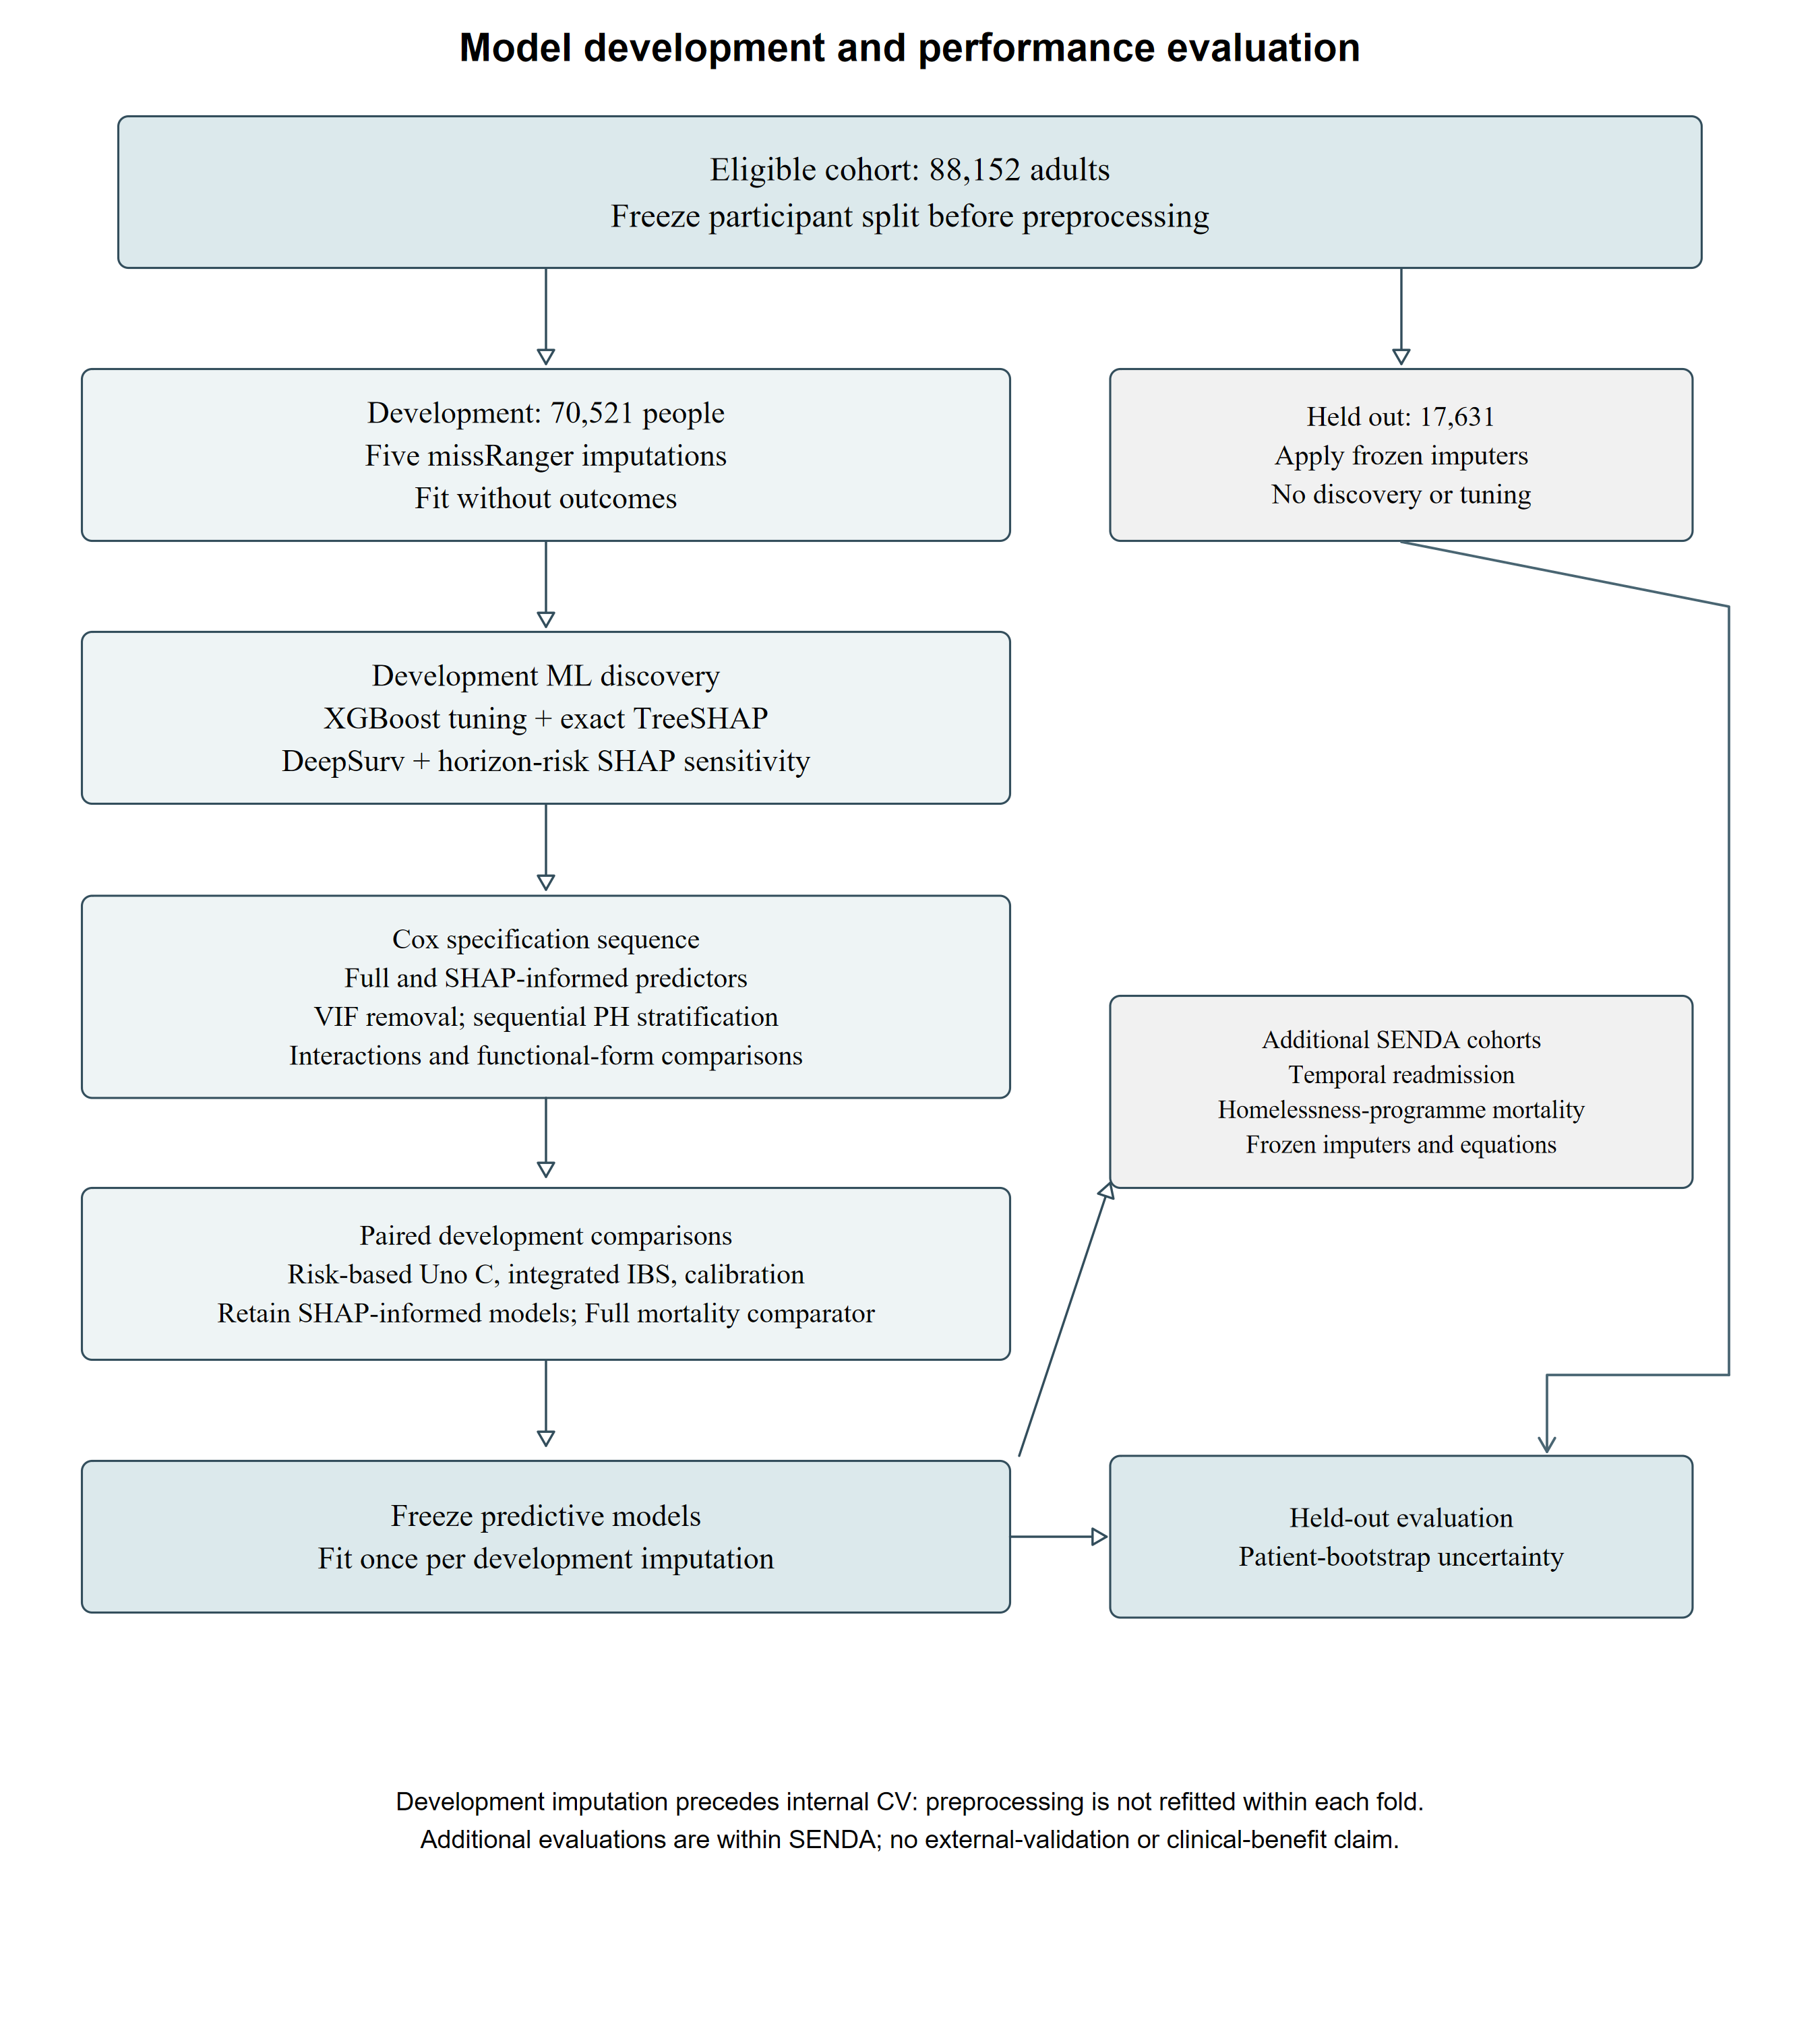

A new workflow figure places partitioning before imputation. Original PPT and Word are unchanged. DeepSurv is a sensitivity branch; its current execution status is listed in the artifact manifest. 


Elapsed: 0.012 minutes


In [20]:
#| label: publication-figure1-workflow
#| message: false
.t0 <- proc.time()
# Put the frozen split before all imputation and show the internal-CV limitation explicitly.
prep<-readRDS(resolve(config$sources$clean_preparation_cache))
nd<-nrow(prep$development);nh<-nrow(prep$holdout)
export_figure("Figure1",function(){
 grid::grid.newpage();grid::grid.text("Model development and performance evaluation",.5,.977,gp=grid::gpar(fontsize=14,fontface="bold"))
 box(.5,.905,.87,.075,paste0("Eligible cohort: ",format(nd+nh,big.mark=",")," adults\nFreeze participant split before preprocessing"),"#dce9ec",12)
 arrow(.30,.867,y2=.82);arrow(.77,.867,y2=.82)
 box(.30,.775,.51,.085,paste0("Development: ",format(nd,big.mark=",")," people\nFive missRanger imputations\nFit without outcomes"),size=11)
 box(.77,.775,.32,.085,paste0("Held out: ",format(nh,big.mark=","),"\nApply frozen imputers\nNo discovery or tuning"),"#f1f1f1",10)
 arrow(.30,.732,y2=.69)
 box(.30,.645,.51,.085,"Development ML discovery\nXGBoost tuning + exact TreeSHAP\nDeepSurv + horizon-risk SHAP sensitivity",size=11)
 arrow(.30,.602,y2=.56)
 box(.30,.507,.51,.10,"Cox specification sequence\nFull and SHAP-informed predictors\nVIF removal; sequential PH stratification\nInteractions and functional-form comparisons",size=10)
 arrow(.30,.457,y2=.418)
 box(.30,.37,.51,.085,"Paired development comparisons\nRisk-based Uno C, integrated IBS, calibration\nRetain SHAP-informed models; Full mortality comparator",size=10)
 arrow(.30,.327,y2=.285)
 box(.30,.24,.51,.075,"Freeze predictive models\nFit once per development imputation",fill="#dce9ec",size=11)
 arrow(.555,.24,x2=.608,y2=.24)
 grid::grid.lines(x=c(.77,.95,.95),y=c(.732,.70,.32),gp=grid::gpar(col="#496572",lwd=1.2))
 grid::grid.lines(x=c(.95,.85,.85),y=c(.32,.32,.282),arrow=grid::arrow(length=grid::unit(2,"mm")),gp=grid::gpar(col="#496572",lwd=1.2))
 box(.77,.24,.32,.08,"Held-out evaluation\nPatient-bootstrap uncertainty",fill="#dce9ec",size=10)
 box(.77,.46,.32,.095,"Additional SENDA cohorts\nTemporal readmission\nHomelessness-programme mortality\nFrozen imputers and equations",fill="#f1f1f1",size=9)
 arrow(.56,.28,x2=.61,y2=.415)
 grid::grid.text("Development imputation precedes internal CV: preprocessing is not refitted within each fold.\nAdditional evaluations are within SENDA; no external-validation or clinical-benefit claim.",.5,.10,gp=grid::gpar(fontsize=9,lineheight=1.25))
},9,10,character(),"publication-figure1-workflow","A new workflow figure places partitioning before imputation. Original PPT and Word are unchanged. DeepSurv is a sensitivity branch; its current execution status is listed in the artifact manifest.")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time()-.t0)["elapsed"])/60))


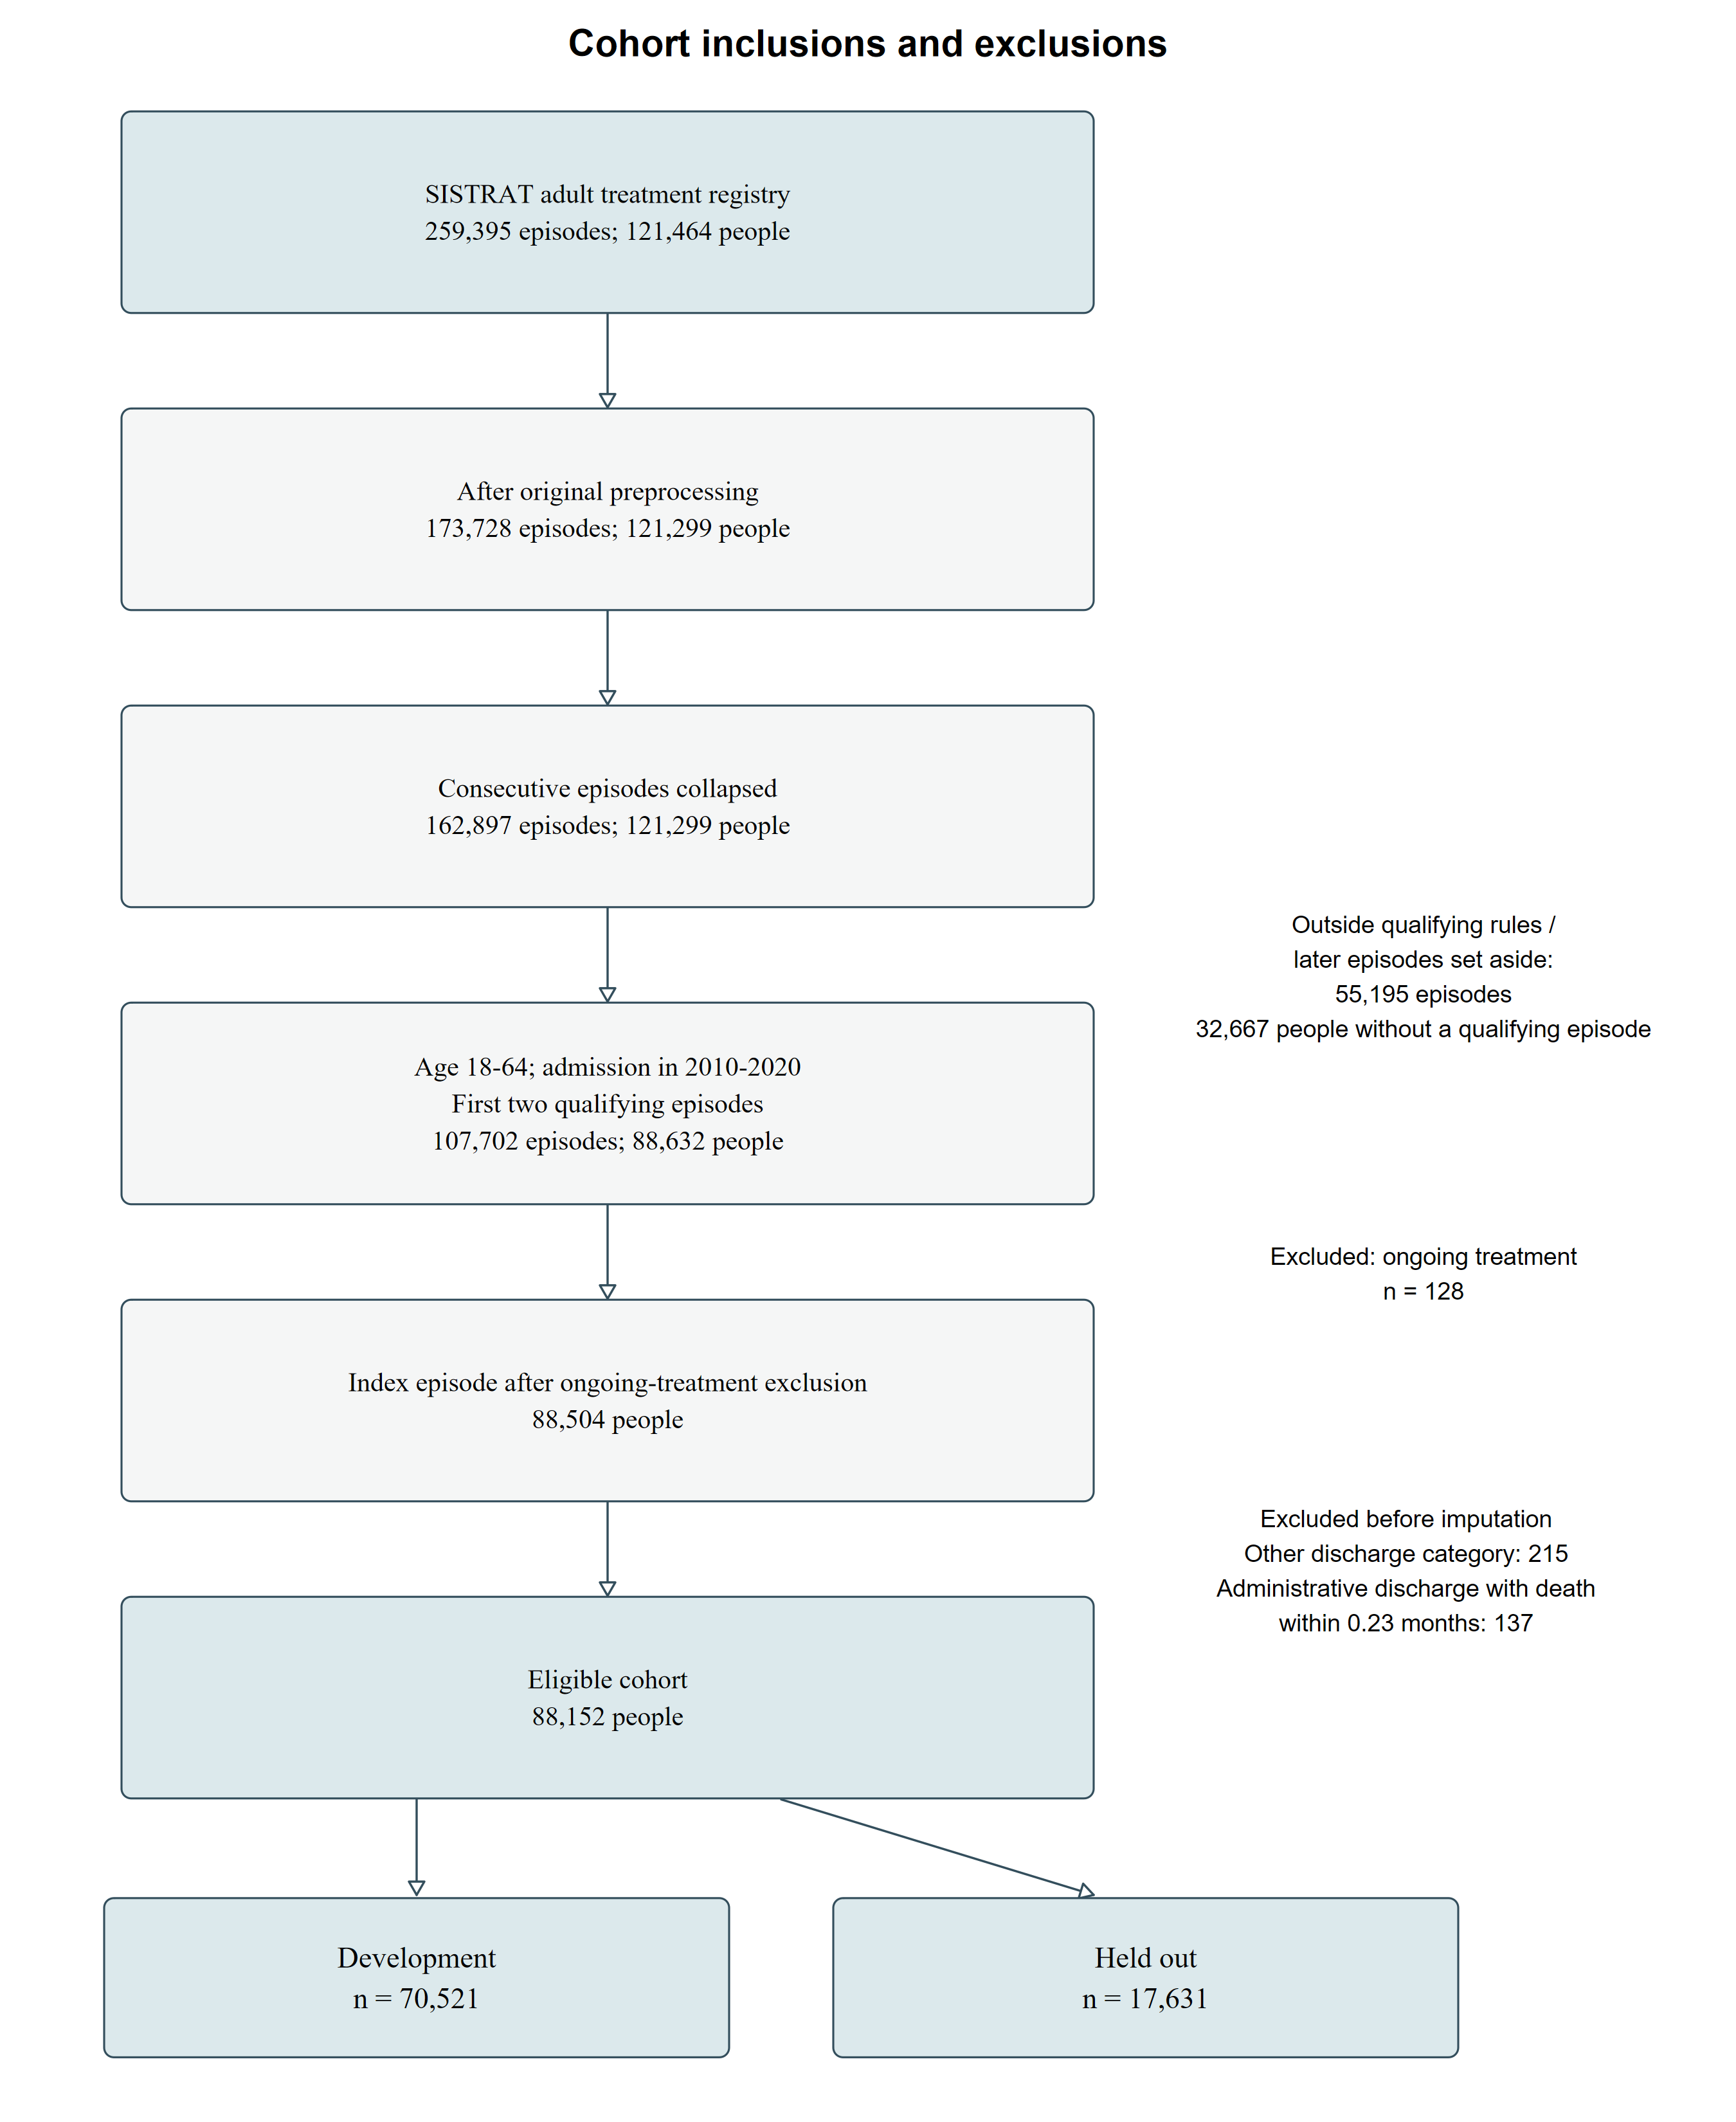

Counts are recomputed from saved source stages and checked against the frozen 00 partition. The 215 exclusions are the invalid other discharge category, not inferred incomplete duration. The historical 0.23-month administrative-death eligibility rule is preserved. 


Elapsed: 0.487 minutes


In [21]:
#| label: publication-efigure1-cohort-counts
#| message: false
.t0 <- proc.time()
# Recount the original saved cohort stages, retaining their exact age/date/episode rules.
a<-readRDS(src("flow_original"));counts<-list(original_rows=nrow(a),original_people=length(unique(a$hash_key)));rm(a);invisible(gc())
env<-new.env(parent=baseenv());invisible(load(src("flow_preprocessed"),envir=env));a<-get("SISTRAT23_c1_2010_2024_df_prev1t",env,inherits=FALSE);counts$pre_rows<-nrow(a);counts$pre_people<-length(unique(a$hash_key));rm(a,env);invisible(gc())
a<-readRDS(src("flow_collapsed"));counts$collapsed_rows<-nrow(a);counts$collapsed_people<-length(unique(a$hash_key))
keep<-!is.na(a$adm_age_rec3)&a$adm_age_rec3>=18&a$adm_age_rec3<=64&!is.na(a$adm_date_rec2)&a$adm_date_rec2>=as.Date("2010-01-01")&a$adm_date_rec2<=as.Date("2020-12-31")
a<-a[keep,c("hash_key","adm_date_rec2","disch_date_rec6","tr_compliance_rec7")];a<-a[order(a$hash_key,a$adm_date_rec2,a$disch_date_rec6),];n<-table(a$hash_key)
counts$qualifying_episodes<-sum(pmin(n,2L));counts$qualifying_people<-length(n);a<-a[!duplicated(a$hash_key),];counts$ongoing<-sum(a$tr_compliance_rec7=="currently in",na.rm=TRUE);counts$missing_compliance<-sum(is.na(a$tr_compliance_rec7));rm(a,n);invisible(gc())
env<-new.env(parent=baseenv());invisible(load(resolve(config$sources$raw_workspace),envir=env));a<-get(config$sources$legacy_raw_object,env,inherits=FALSE)
ev<-as.integer(as.character(a$death_event));if(all(ev%in%c(1L,2L)))ev<-ev-1L;stopifnot(all(ev%in%0:1))
other<-grepl("other",as.character(a$tr_outcome),ignore.case=TRUE);artifact<-grepl("adm reasons",as.character(a$tr_outcome),ignore.case=TRUE)&ev==1L&as.numeric(a$death_time_from_disch_m)<=.23
counts$other<-sum(other);counts$artifact<-sum(artifact);counts$overlap<-sum(other&artifact);counts$eligible<-sum(!(other|artifact));counts$development<-nd;counts$holdout<-nh
stopifnot(counts$eligible==nd+nh,counts$qualifying_people-counts$ongoing-counts$missing_compliance==nrow(a),counts$overlap==0L)
rm(a,env);invisible(gc());flow_source<-data.frame(Stage=names(counts),N=unlist(counts))
p<-file.path(resolve(config$paths$tables),paste0("eFigure1_cohort_counts_",Sys.Date(),"_",publication_signature,".csv"));utils::write.csv(flow_source,p,row.names=FALSE);written<-c(written,p)
f<-function(n)format(n,big.mark=",",trim=TRUE,scientific=FALSE)
export_figure("eFigure1",function(){
 grid::grid.newpage();grid::grid.text("Cohort inclusions and exclusions",.5,.98,gp=grid::gpar(fontsize=14,fontface="bold"))
 ys<-c(.90,.76,.62,.48,.34,.20)
 texts<-c(paste0("SISTRAT adult treatment registry\n",f(counts$original_rows)," episodes; ",f(counts$original_people)," people"),paste0("After original preprocessing\n",f(counts$pre_rows)," episodes; ",f(counts$pre_people)," people"),paste0("Consecutive episodes collapsed\n",f(counts$collapsed_rows)," episodes; ",f(counts$collapsed_people)," people"),paste0("Age 18-64; admission in 2010-2020\nFirst two qualifying episodes\n",f(counts$qualifying_episodes)," episodes; ",f(counts$qualifying_people)," people"),paste0("Index episode after ongoing-treatment exclusion\n",f(counts$qualifying_people-counts$ongoing-counts$missing_compliance)," people"),paste0("Eligible cohort\n",f(counts$eligible)," people"))
 for(i in seq_along(ys)){box(.35,ys[i],.56,.095,texts[i],if(i%in%c(1,6))"#dce9ec" else "#f5f6f6",10);if(i<length(ys))arrow(.35,ys[i]-.048,y2=ys[i+1]+.048)}
 grid::grid.text(paste0("Outside qualifying rules /\nlater episodes set aside:\n",f(counts$collapsed_rows-counts$qualifying_episodes)," episodes\n",f(counts$collapsed_people-counts$qualifying_people)," people without a qualifying episode"),.82,.54,gp=grid::gpar(fontsize=9))
 grid::grid.text(paste0("Excluded: ongoing treatment\nn = ",f(counts$ongoing)),.82,.40,gp=grid::gpar(fontsize=9))
 grid::grid.text(paste0("Excluded before imputation\nOther discharge category: ",f(counts$other),"\nAdministrative discharge with death\nwithin 0.23 months: ",f(counts$artifact)),.81,.26,gp=grid::gpar(fontsize=9))
 arrow(.24,.152,x2=.24,y2=.107);arrow(.45,.152,x2=.63,y2=.107)
 box(.24,.068,.36,.075,paste0("Development\nn = ",f(nd)),"#dce9ec",11);box(.66,.068,.36,.075,paste0("Held out\nn = ",f(nh)),"#dce9ec",11)
},9,11,c("flow_original","flow_preprocessed","flow_collapsed"),"publication-efigure1-cohort-counts","Counts are recomputed from saved source stages and checked against the frozen 00 partition. The 215 exclusions are the invalid other discharge category, not inferred incomplete duration. The historical 0.23-month administrative-death eligibility rule is preserved.")
trace$eFigure1$Numeric_output<-substring(p,nchar(root)+2L)
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time()-.t0)["elapsed"])/60))


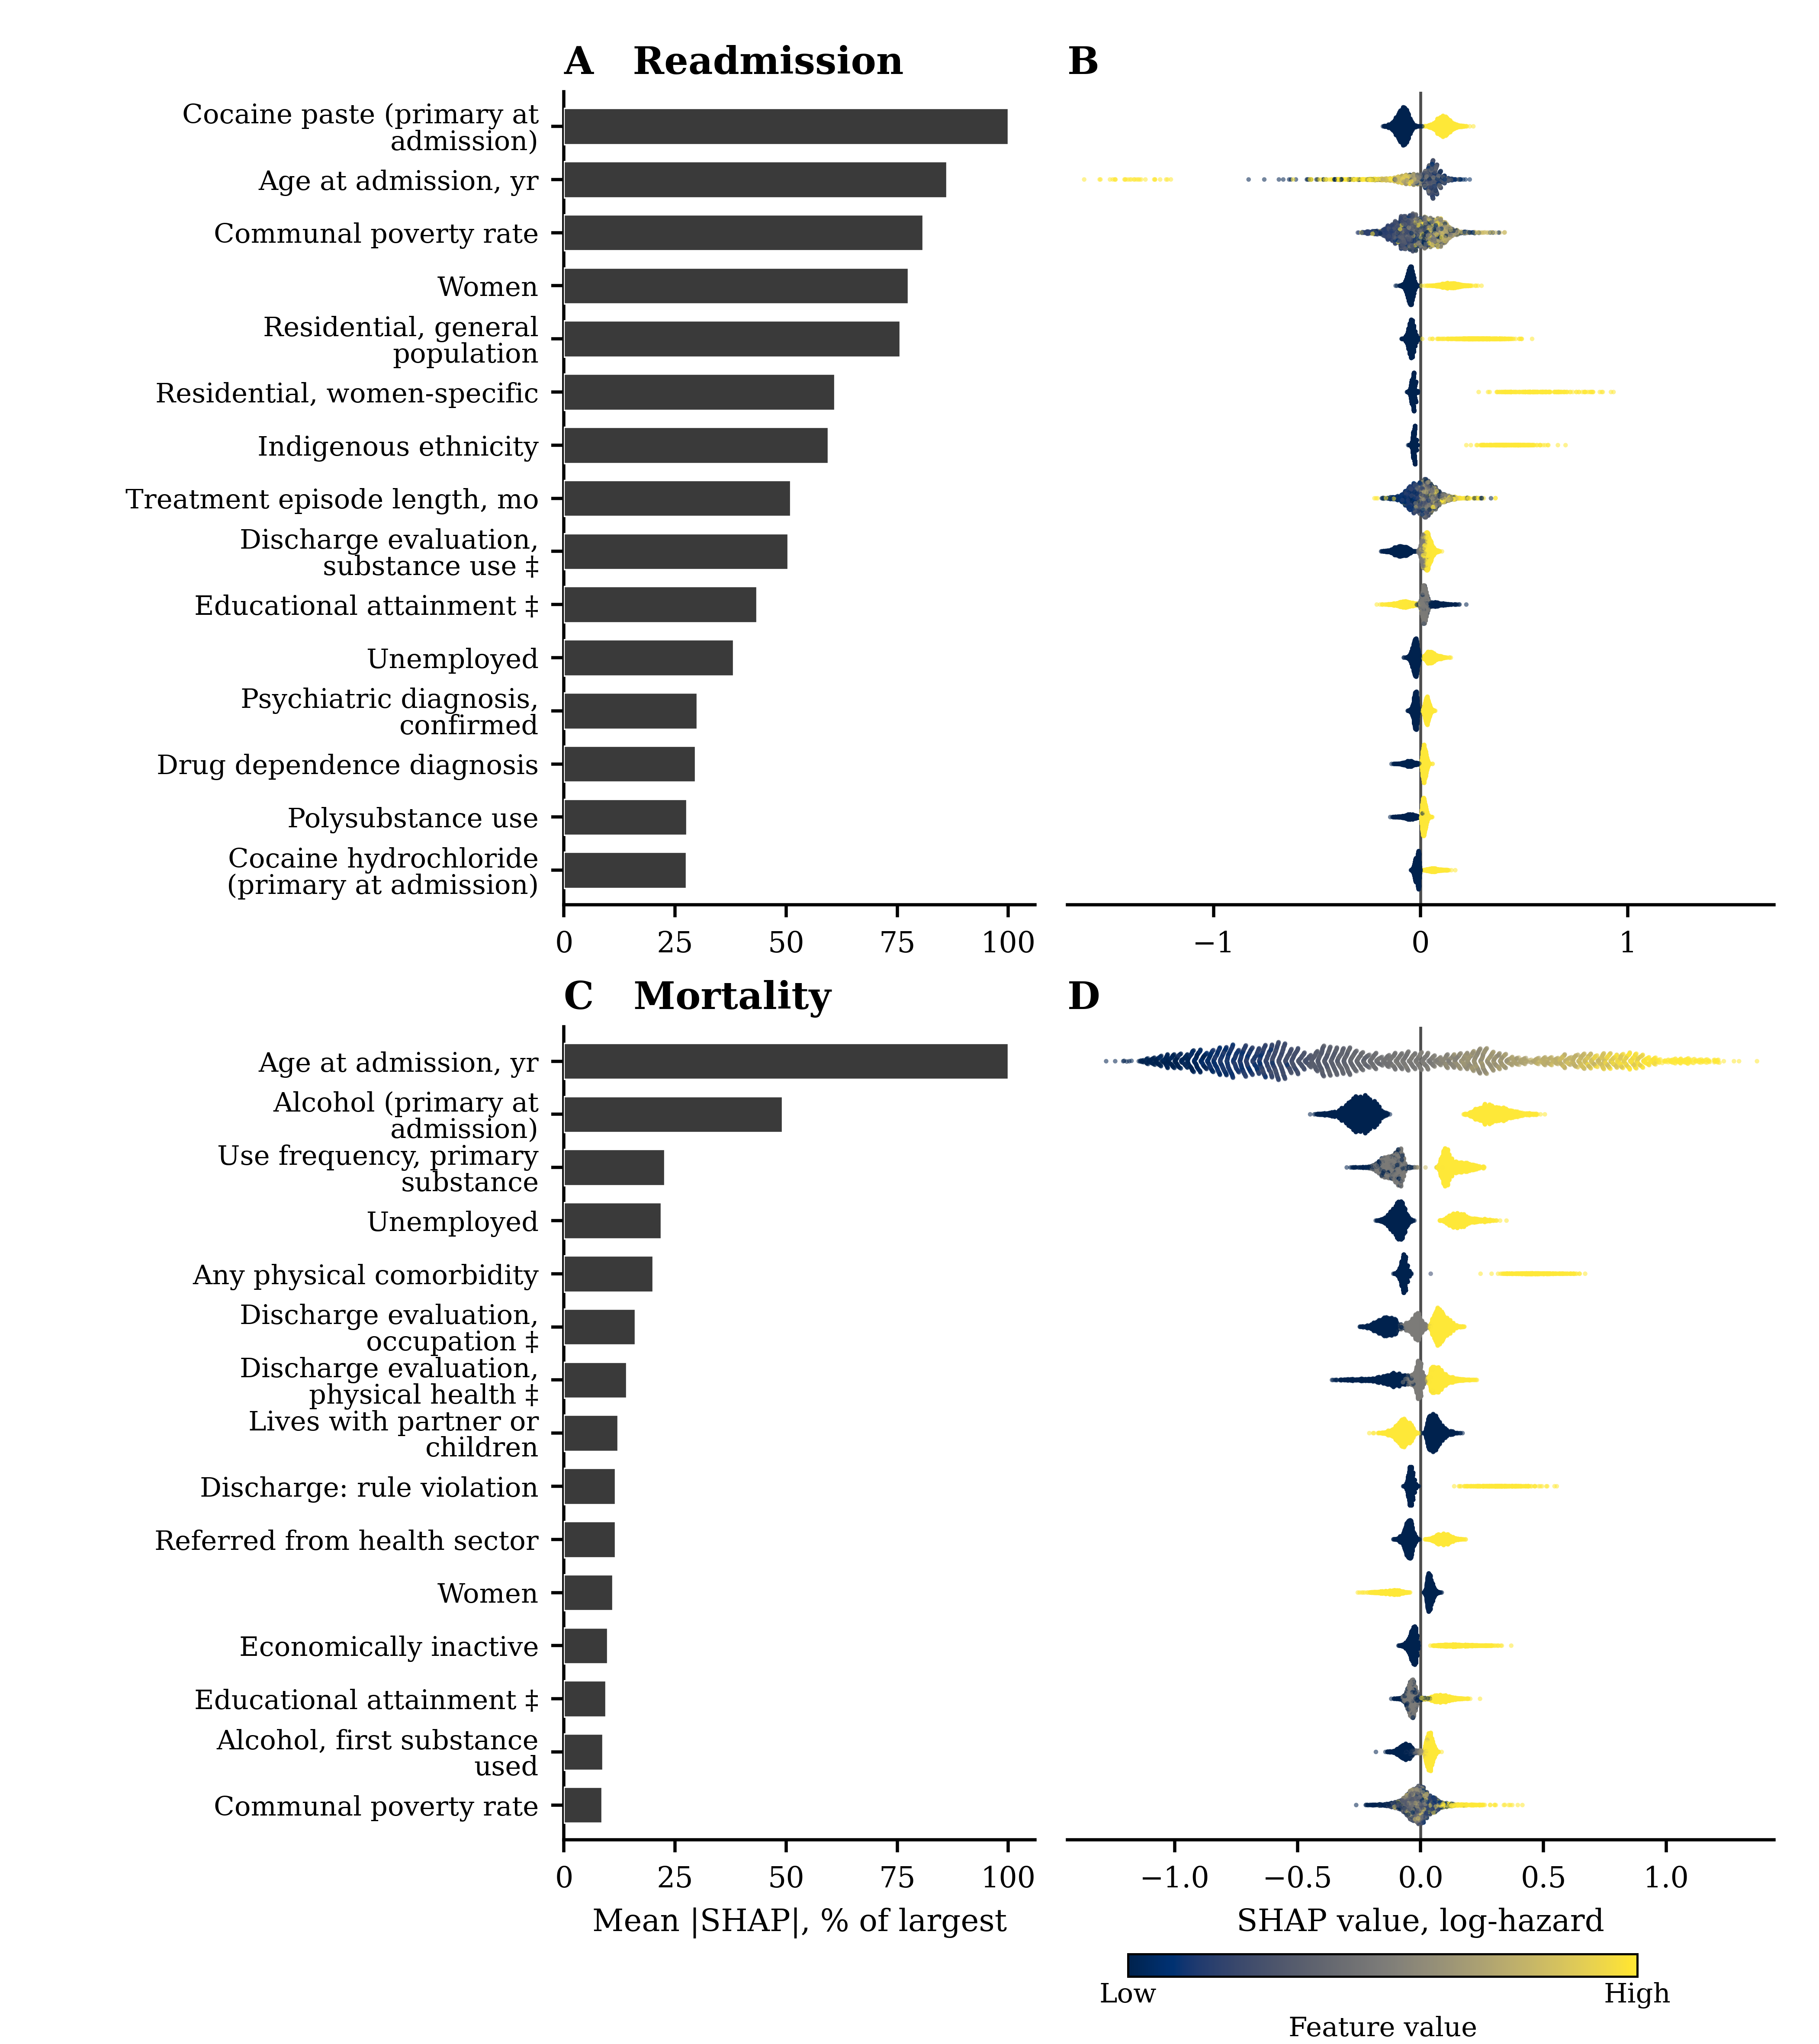

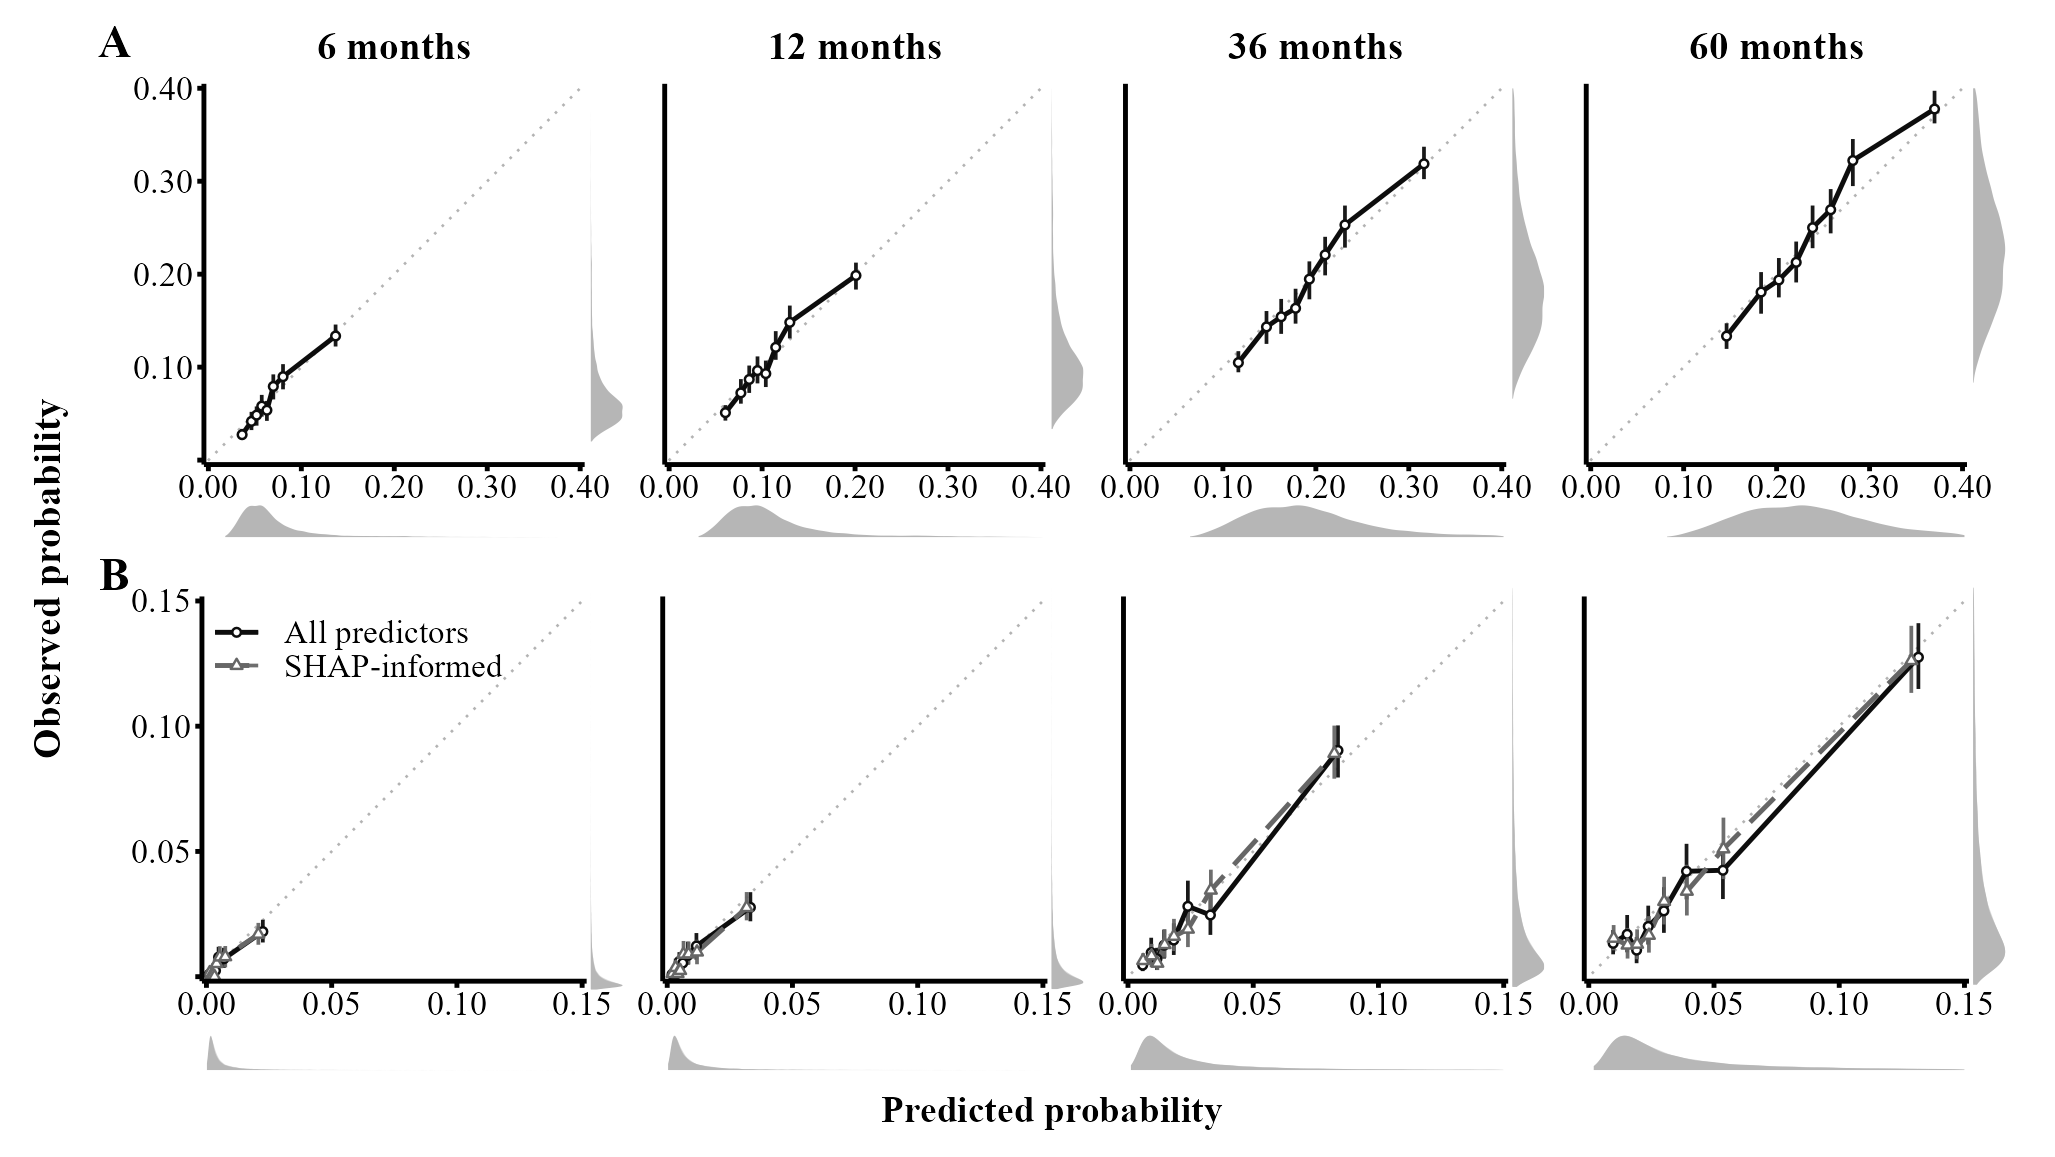

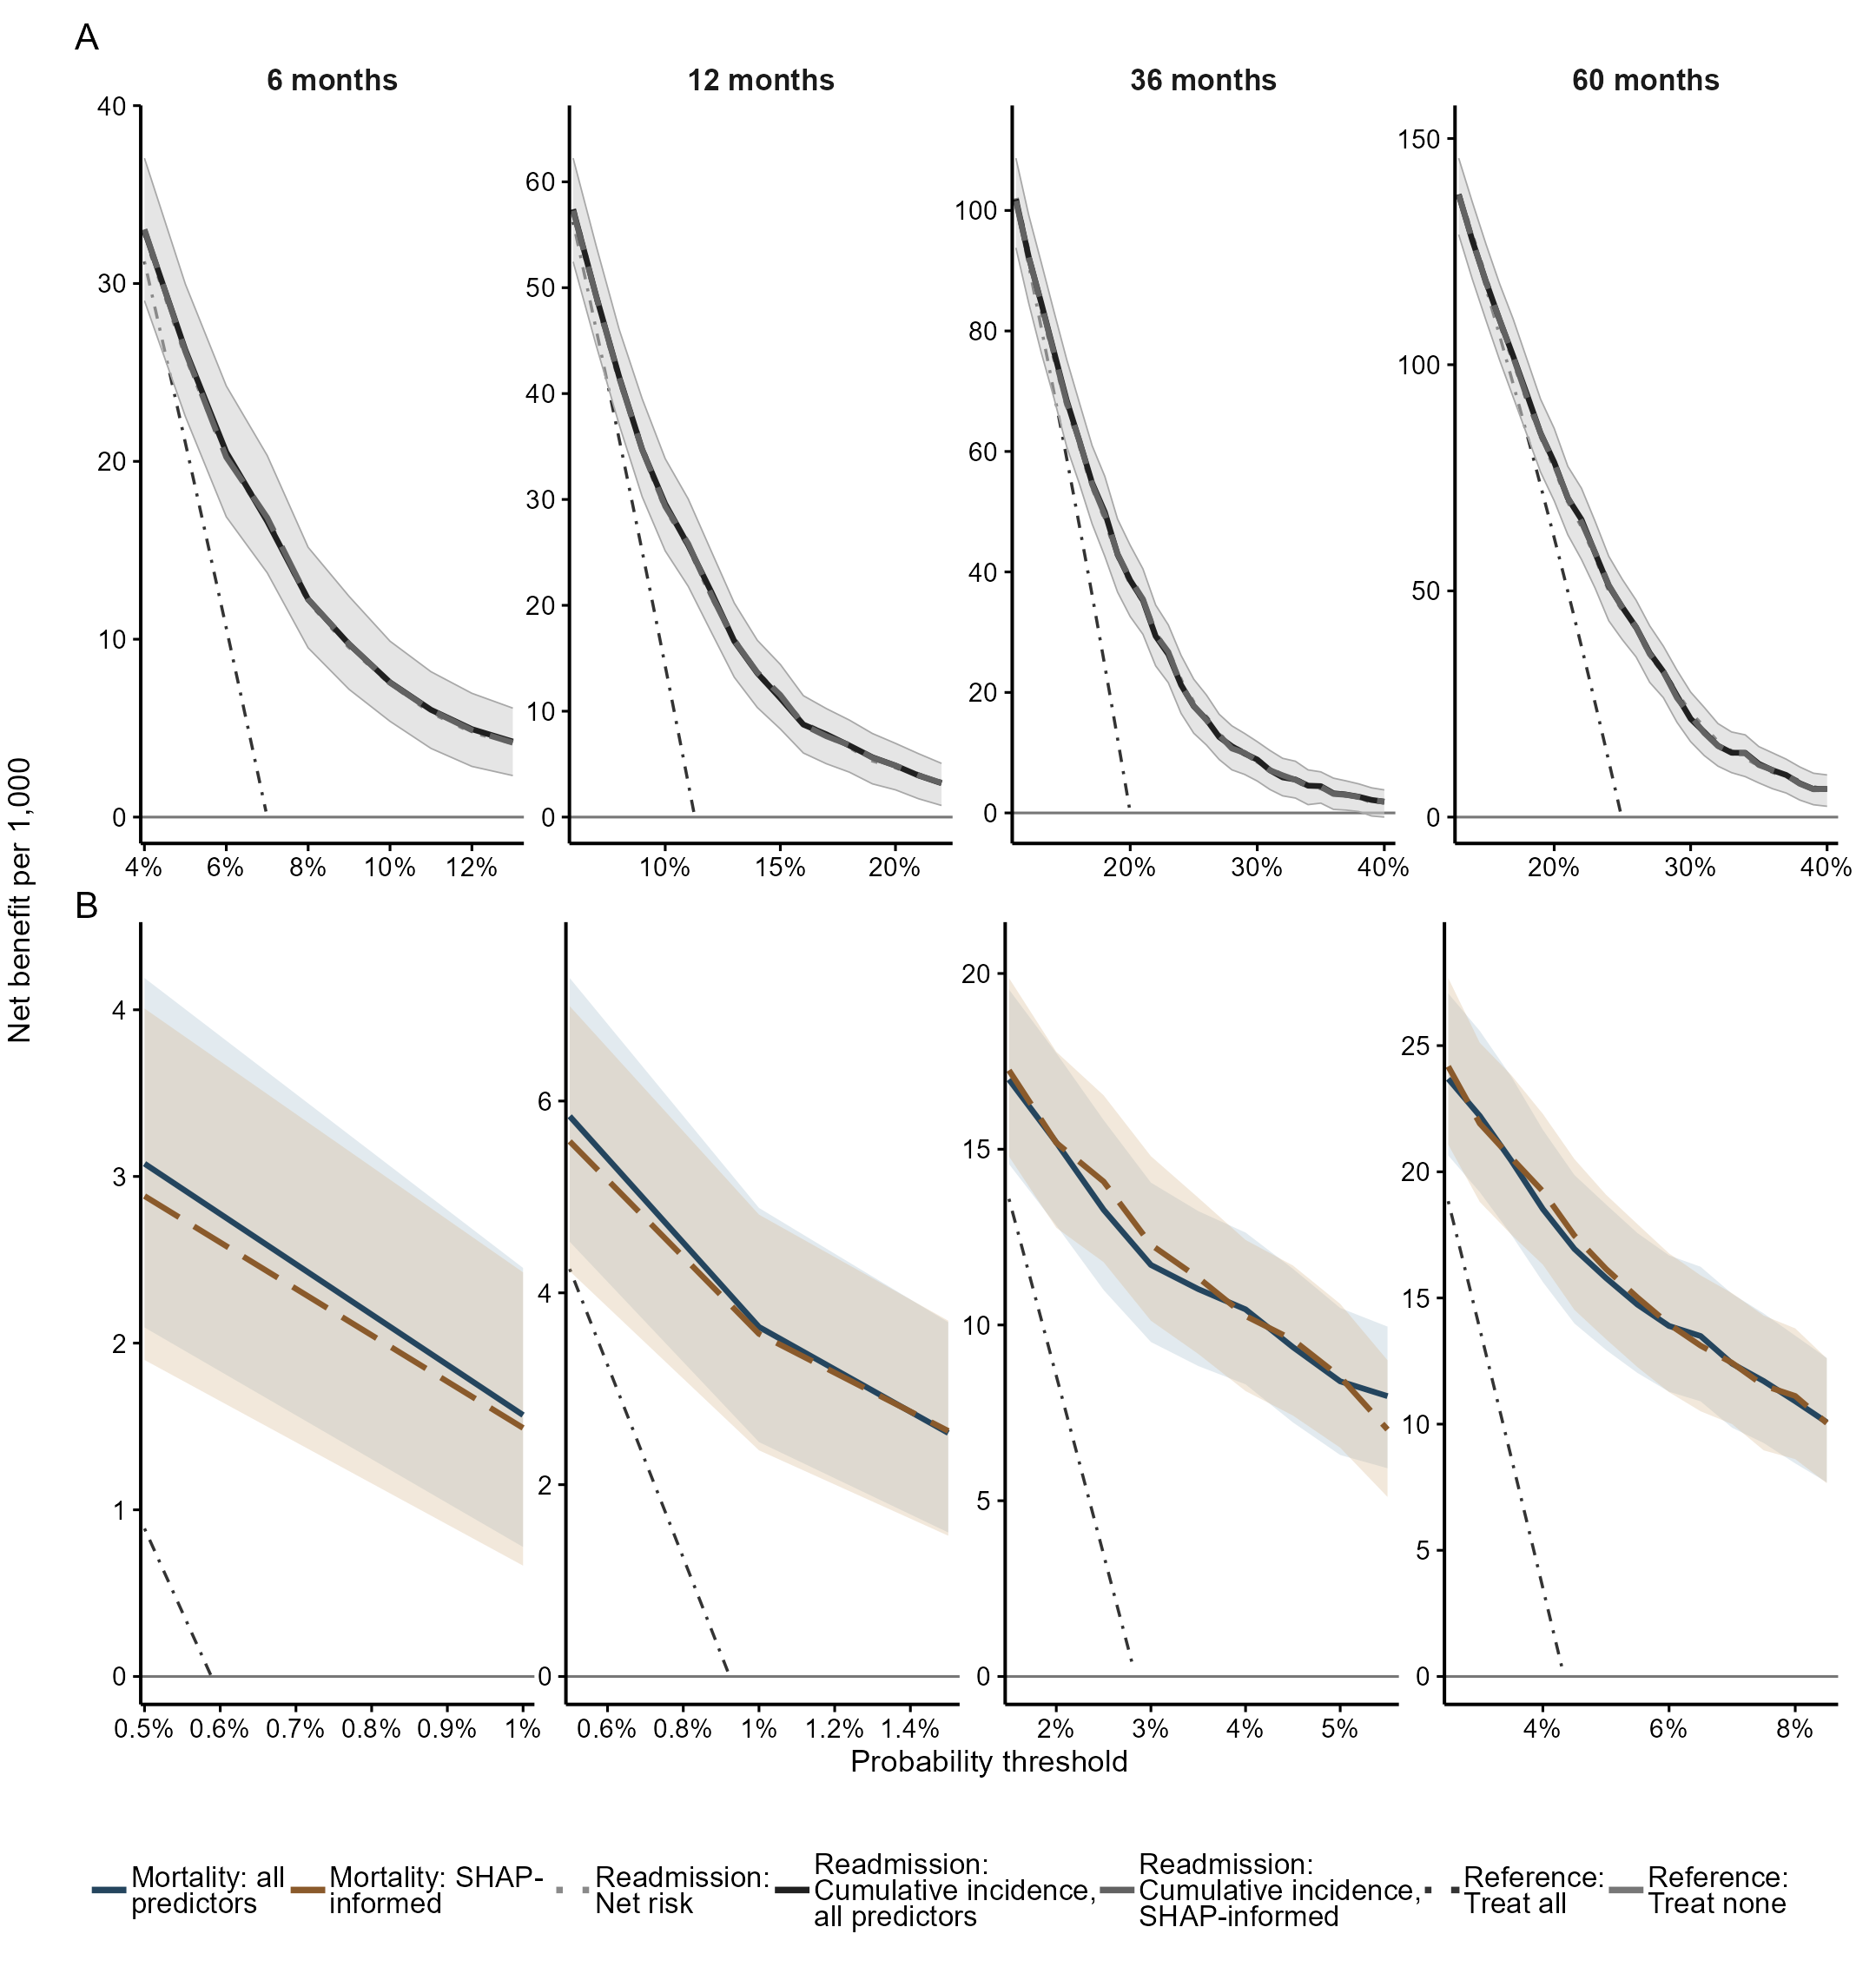

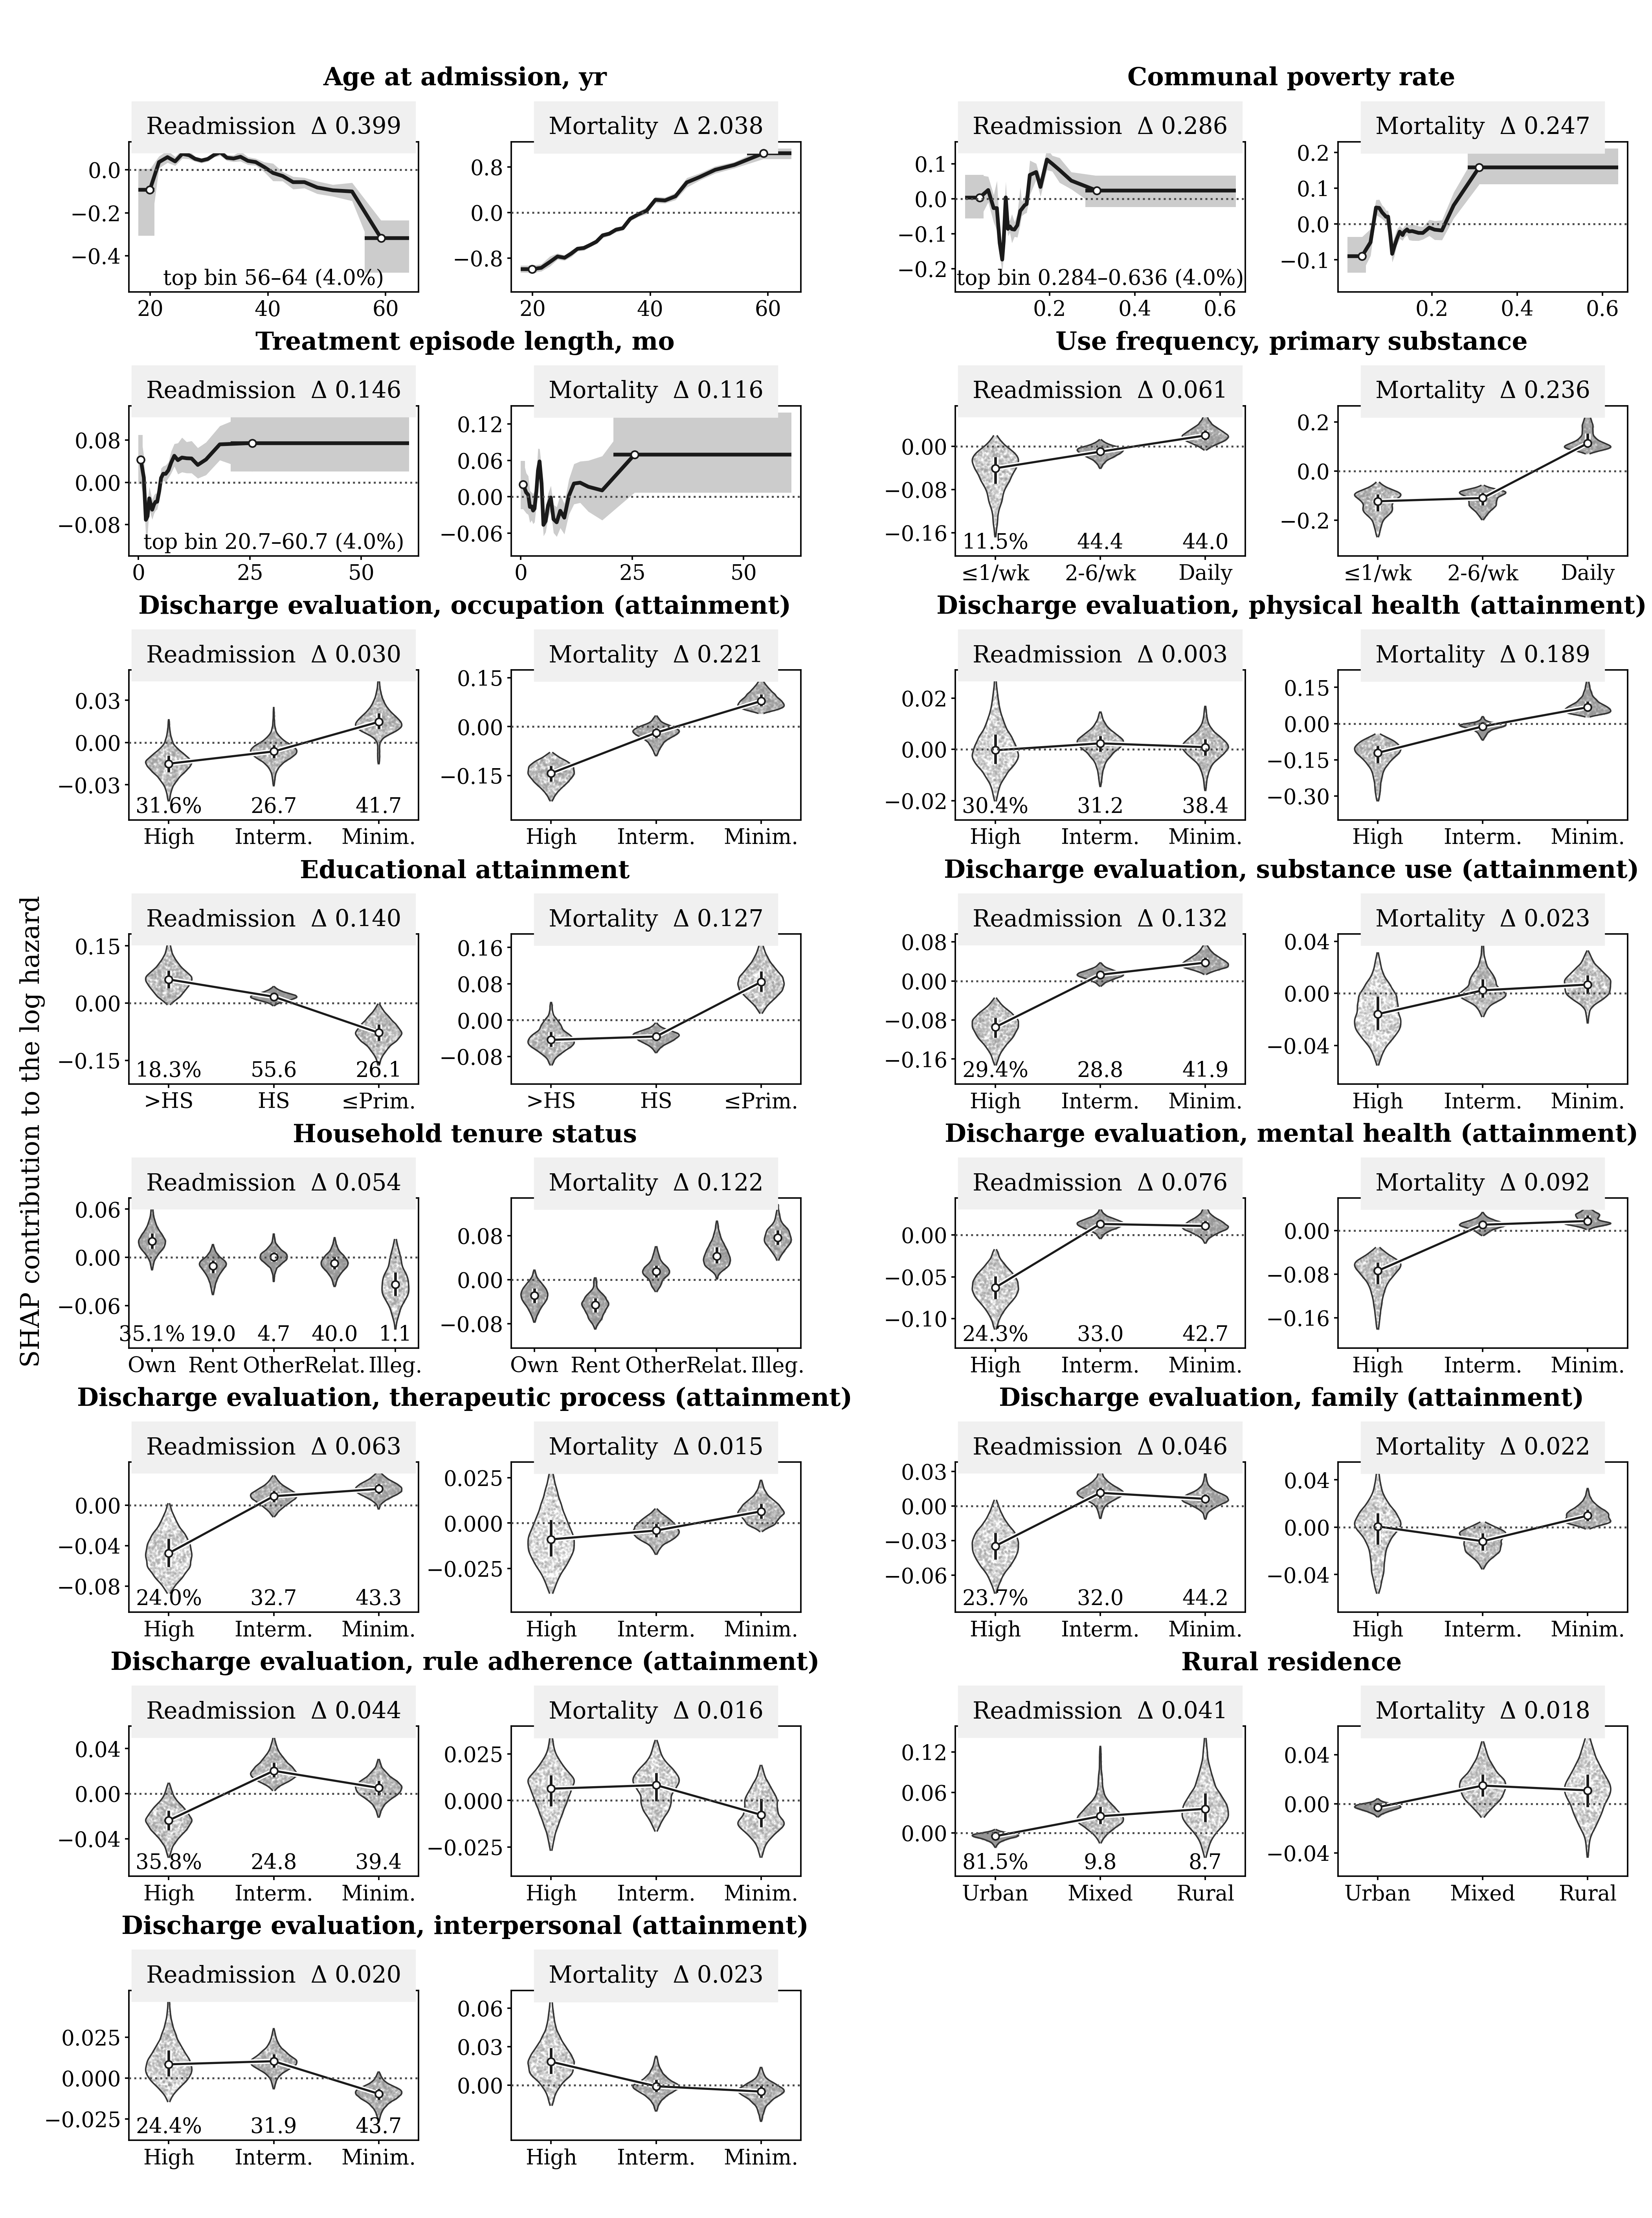

Maximum mean absolute log-hazard SHAP: Death 0.542; Readmission 0.097 . Exact TreeSHAP, current predictors. 
Grouped held-out calibration; the readmission panel uses CIF from b with e. Mortality shows d/e. Five imputation predictions pooled; 1,000 bootstrap intervals. 
Held-out net-benefit curves. Corrected serif font and complete Treat none legend. Threshold scenarios do not establish clinical benefit. 
Current SHAP functional-form summaries; distributions and interquartile spread are not confidence intervals. No causal interpretation. 


Elapsed: 0.022 minutes


In [22]:
#| label: publication-existing-scientific-figures
#| message: false
.t0 <- proc.time()
# Copy current verified plot files; do not redraw or refit their scientific calculations.
for(id in c("Figure2","Figure3","Figure4","eFigure2")){
 keys<-names(sources)[startsWith(names(sources),paste0(id,"_"))];keys<-keys[grepl("[.](png|pdf|tiff)$",unlist(sources[keys]))]
 paths<-vapply(keys,function(key){from<-src(key);to<-file.path(resolve(config$paths$figures),paste0(id,"_manuscript_",Sys.Date(),"_",publication_signature,".",tools::file_ext(from)));stopifnot(file.copy(from,to,overwrite=TRUE),identical(digest::digest(file=from,algo="sha256"),digest::digest(file=to,algo="sha256")));to},character(1))
 written<-c(written,paths);IRdisplay::display_png(file=paths[grepl("[.]png$",paths)])
 note<-if(id=="Figure2"){x<-read_table("eTable3_1");peaks<-stats::aggregate(mean_abs_shap_log_hazard~outcome,x,max);paste("Maximum mean absolute log-hazard SHAP:",paste(paste(peaks$outcome,fmt(peaks$mean_abs_shap_log_hazard)),collapse="; "),". Exact TreeSHAP, current predictors.")}else if(id=="Figure3")"Grouped held-out calibration; the readmission panel uses CIF from b with e. Mortality shows d/e. Five imputation predictions pooled; 1,000 bootstrap intervals." else if(id=="Figure4")"Held-out net-benefit curves. Corrected serif font and complete Treat none legend. Threshold scenarios do not establish clinical benefit." else "Current SHAP functional-form summaries; distributions and interquartile spread are not confidence intervals. No causal interpretation."
 trace[[id]]<-data.frame(Artifact=id,Notebook="notebooks/13_manuscript_tables_figures.ipynb",Cell="publication-existing-scientific-figures",Upstream_notebook=paste(vapply(items[[id]]$producers,`[[`,character(1),"notebook"),collapse="; "),Upstream_cell=paste(vapply(items[[id]]$producers,`[[`,character(1),"cell"),collapse="; "),Inputs=paste(unlist(sources[keys]),collapse="; "),Output=substring(paths[grepl("[.]pdf$",paths)][1],nchar(root)+2L),Numeric_output=paste(unlist(sources[names(sources)[startsWith(names(sources),paste0(id,"_"))&grepl("[.]csv$",unlist(sources))]]),collapse="; "),Rows=NA_integer_,Status="byte-identical to verified current scientific export")
 packet[[id]]<-list(caption=items[[id]]$caption,files=paths,notes=note);cat(note,"\n")
}
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time()-.t0)["elapsed"])/60))


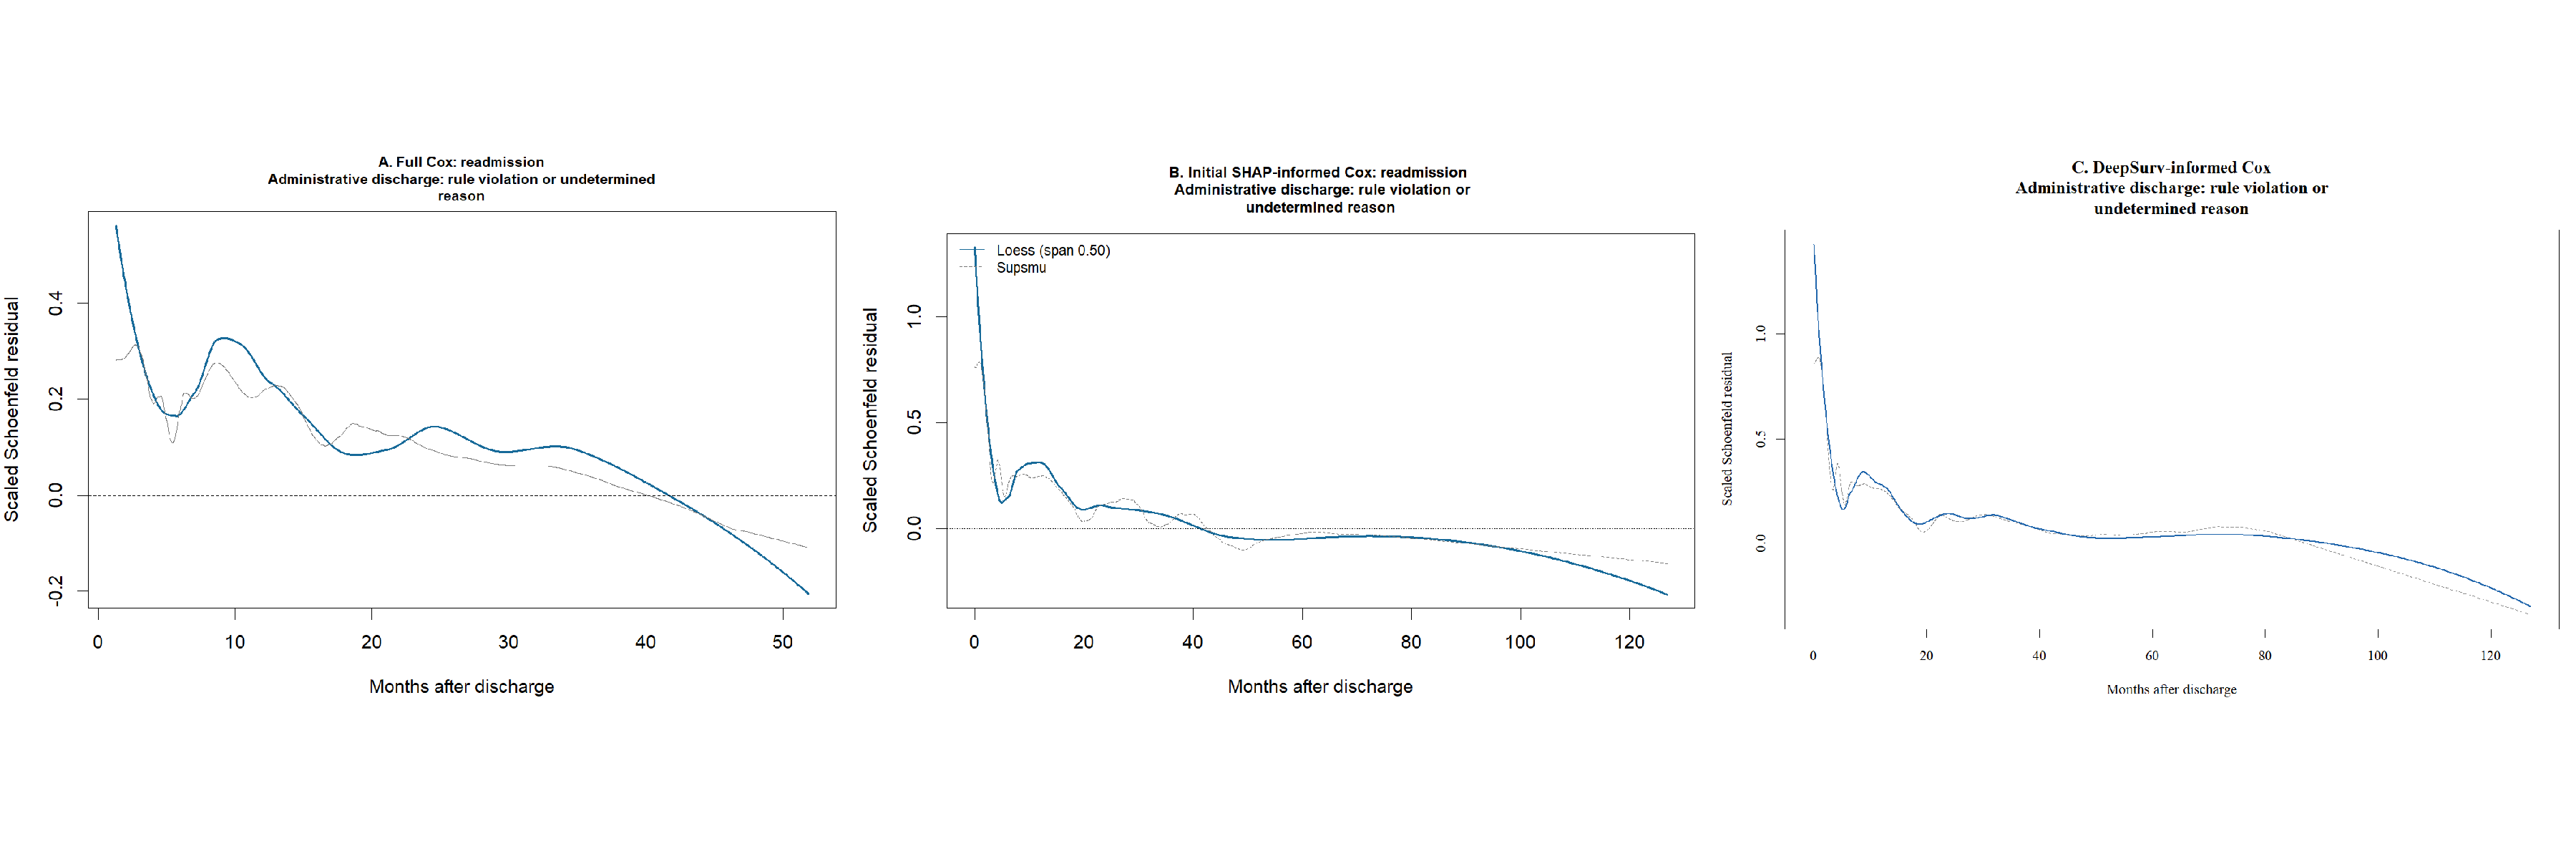

A: Full Cox; B: XGBoost SHAP-informed Cox. First-imputation development diagnostics before the indicated stratification. The completed panels retain their exact source rendering. C: newly computed DeepSurv-informed Cox diagnostics. 


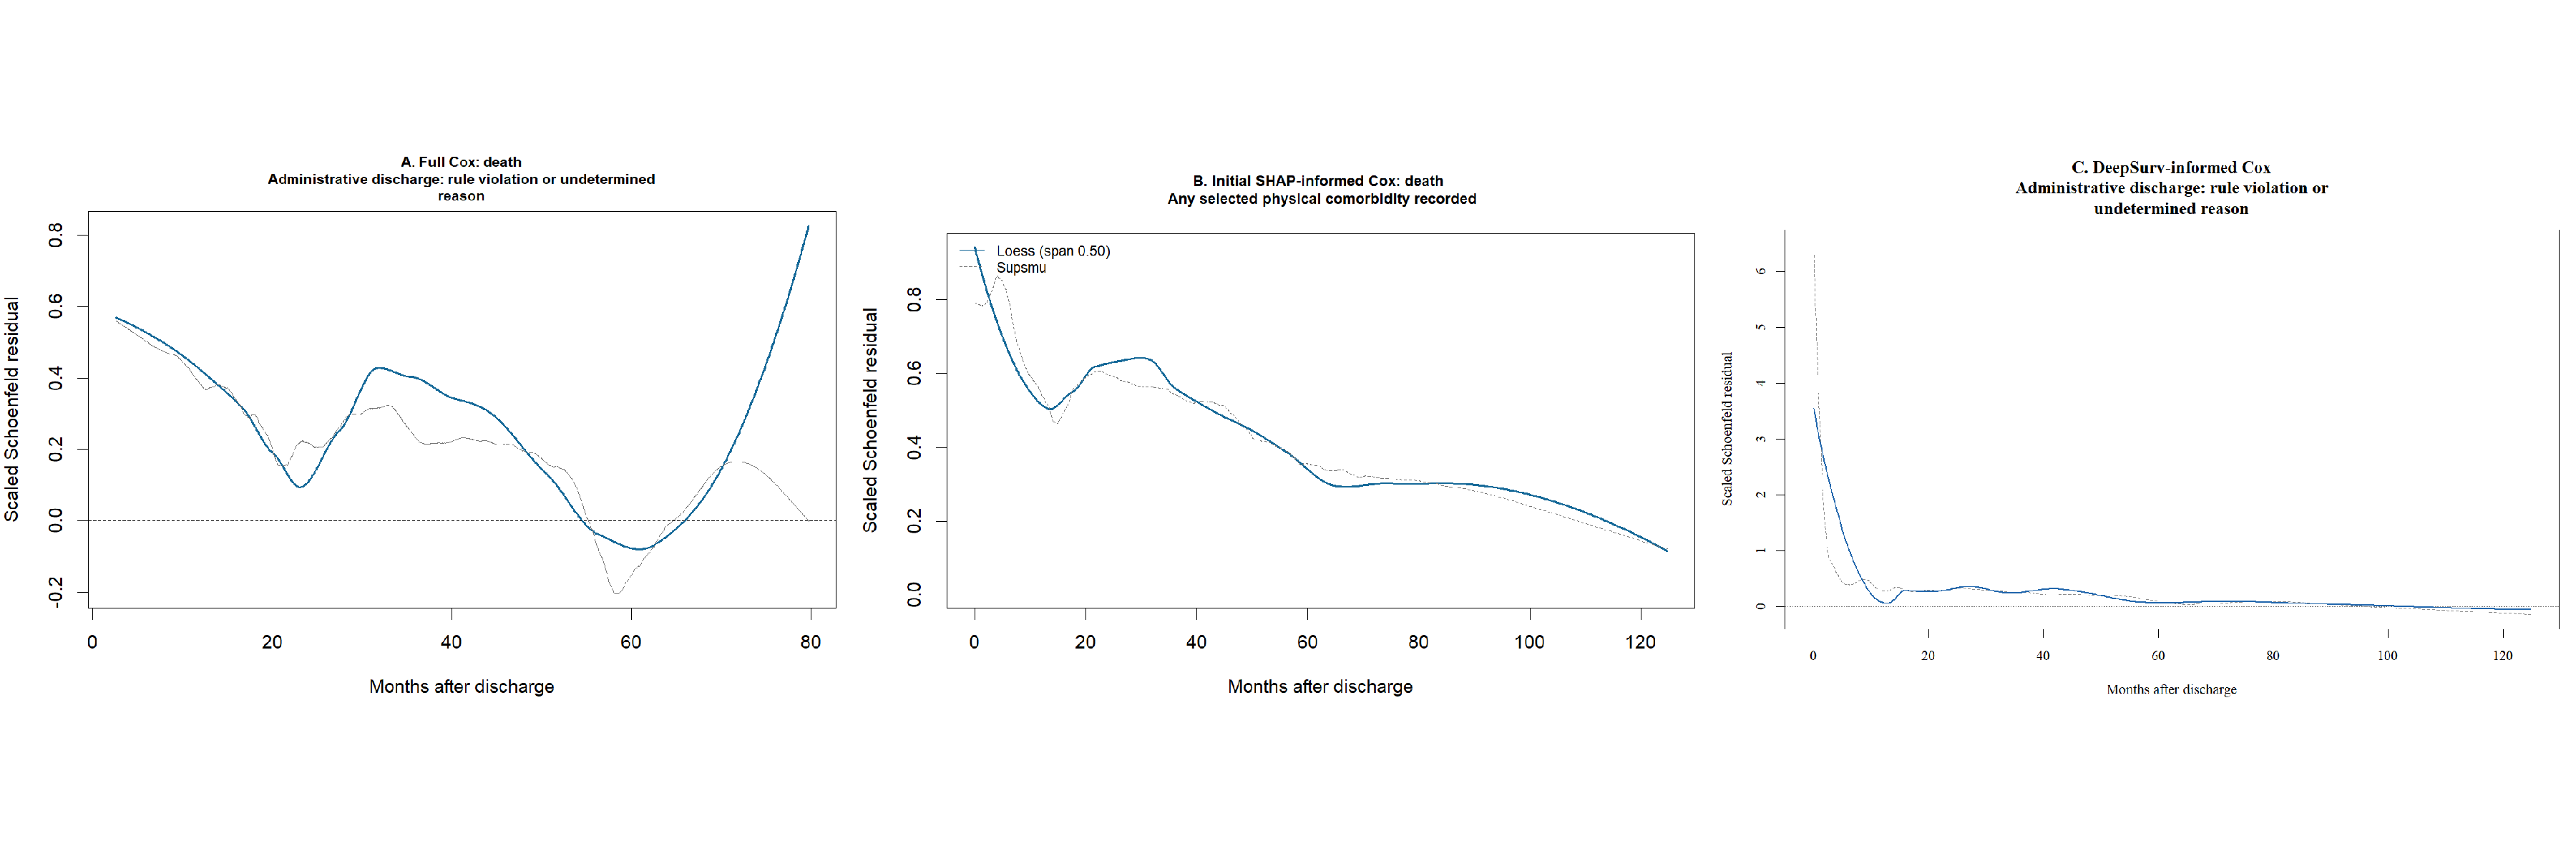

A: Full Cox; B: XGBoost SHAP-informed Cox. First-imputation development diagnostics before the indicated stratification. The completed panels retain their exact source rendering. C: newly computed DeepSurv-informed Cox diagnostics. 


Elapsed: 0.024 minutes


In [23]:
#| label: publication-efigures3-4-ph-panels
#| message: false
.t0 <- proc.time()
# Compose completed PH panels without repeating diagnostics or changing their smoothers.
for(id in c("eFigure3","eFigure4")) {
 keys<-c(paste0(id,"_1"),paste0(id,"_2"));if(paste0(id,"_DS")%in%names(sources))keys<-c(keys,paste0(id,"_DS"))
 panels<-lapply(keys,function(k)png::readPNG(src(k)))
 if(length(keys)==3L)items[[id]]$producers<-c(items[[id]]$producers,list(list(notebook="notebooks/12_prediction24_converted_mod.ipynb",cell="ds-cox-export-ph-panels")))
 export_figure(id,function(){grid::grid.newpage();for(i in seq_along(panels)){grid::pushViewport(grid::viewport(x=(i-.5)/length(panels),y=.51,width=1/length(panels),height=.9));grid::grid.raster(panels[[i]],width=grid::unit(1,"npc"),interpolate=FALSE);grid::popViewport()}},12,4,keys,"publication-efigures3-4-ph-panels",paste0("A: Full Cox; B: XGBoost SHAP-informed Cox. First-imputation development diagnostics before the indicated stratification. The completed panels retain their exact source rendering. ",if(length(keys)==3L)"C: newly computed DeepSurv-informed Cox diagnostics."else "DeepSurv panel C remains pending."))
 if(length(keys)==2L)pending<-c(pending,paste(id,"DeepSurv panel C"))
}
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time()-.t0)["elapsed"])/60))


In [24]:
#| label: publication-manifest-and-packet
#| message: false
.t0 <- proc.time()
# Make every current publication artifact and producing cell discoverable in one small index.
if(!all(c("eTable7","eTable8","eTable9")%in%names(packet)))pending<-c(pending,"eTables7-9 and Table2 DeepSurv blocks: clean sensitivity branch pending")
manifest<-do.call(rbind,trace);stopifnot(!anyDuplicated(manifest$Artifact),all(file.exists(file.path(root,manifest$Output))))
mp<-file.path(resolve(config$paths$tables),paste0("manuscript_artifact_traceability_",Sys.Date(),"_",publication_signature,".csv"));utils::write.csv(manifest,mp,row.names=FALSE);written<-c(written,mp)
sections<-vapply(names(packet),function(id){v<-packet[[id]];if(!is.null(v$html)){body<-sub("^.*<h1>","<h1>",v$html);body<-sub("</body></html>$|</html>$","",body);body}else{png<-v$files[grepl("[.]png$",v$files)][1];paste0('<h1>',htmltools::htmlEscape(v$caption),'</h1><img style="max-width:100%" alt="',htmltools::htmlEscape(v$caption),'" src="../figures/',basename(png),'"><p>',htmltools::htmlEscape(v$notes),'</p>')}},character(1))
index<-file.path(resolve(config$paths$tables),paste0("Article2_manuscript_artifacts_",Sys.Date(),"_",publication_signature,".html"))
writeLines(paste0('<!doctype html><html lang="en"><meta charset="utf-8"><title>Article 2 manuscript artifacts</title><style>',css,'</style><h1>Current manuscript artifacts</h1><p>Executed sources only. Pending: ',htmltools::htmlEscape(paste(pending,collapse="; ")),'.</p>',paste(sections,collapse='<hr>'),'</html>'),index,useBytes=TRUE);written<-c(written,index)
show_table(manifest[,c("Artifact","Cell","Rows","Status")],"Artifact-to-cell traceability")
cat("Pending:",paste(pending,collapse="; "),"\n")
stopifnot(identical(digest::digest(file=resolve(config$sources$manuscript),algo="sha256"),word_sha))
record<-list(status=if(length(pending))"non_deepsurv_packet_with_explicit_pending_items" else "complete_publication_packet",signature=publication_signature,created_at=format(Sys.time(),"%Y-%m-%dT%H:%M:%S%z"),manuscript_sha256=word_sha,manuscript_unchanged=TRUE,artifacts=names(packet),pending=pending,source_hashes=source_hashes,traceability=substring(mp,nchar(root)+2L),index=substring(index,nchar(root)+2L),new_model_fits=0L)
jsonlite::write_json(record,file.path(resolve(config$paths$docs),"13_publication_artifact_record.json"),pretty=TRUE,auto_unbox=TRUE)
if(isTRUE(config$publication$require_complete))stopifnot(!length(pending),length(packet)==27L)
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time()-.t0)["elapsed"])/60))


Artifact,Cell,Rows,Status
Table1,publication-table1,473,current executed sources
Table2,publication-table2,20,current executed sources
Table3,publication-table3,12,current executed sources
Table4,publication-table4,28,current executed sources
eTable1,publication-etable1-definitions,25,current executed sources
eTable2,publication-etable2-xgboost-tuning,16,current executed sources
eTable3,publication-etable3-xgboost-shap,110,current executed sources
eTable4,publication-etable4-interaction-screening,9,current executed sources
eTable5,publication-etables5-6-functional-forms,52,current executed sources
eTable6,publication-etables5-6-functional-forms,104,current executed sources


Pending:  


Elapsed: 0.004 minutes


## Session info

In [25]:
#| label: publication-session-info
#| message: false
.t0 <- proc.time()
print(utils::sessionInfo())
cat("No predictive model, imputer, tuning, SHAP or bootstrap was recomputed in this assembly notebook.\n")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time()-.t0)["elapsed"])/60))


R version 4.4.1 (2024-06-14 ucrt)
Platform: x86_64-w64-mingw32/x64
Running under: Windows 11 x64 (build 26200)

Matrix products: default


locale:
[1] LC_COLLATE=Spanish_Chile.utf8       LC_CTYPE=English_United States.utf8
[3] LC_MONETARY=Spanish_Chile.utf8      LC_NUMERIC=C                       
[5] LC_TIME=Spanish_Chile.utf8         

time zone: America/Santiago
tzcode source: internal

attached base packages:
[1] stats     graphics  grDevices utils     datasets  methods   base     

loaded via a namespace (and not attached):
 [1] crayon_1.5.3       vctrs_0.7.3        cli_3.6.4          knitr_1.50        
 [5] rlang_1.2.0        xfun_0.57          png_0.1-8          generics_0.1.3    
 [9] jsonlite_1.9.1     glue_1.8.0         listenv_0.9.1      htmltools_0.5.8.1 
[13] IRdisplay_1.1      IRkernel_1.3.2     scales_1.4.0       grid_4.4.1        
[17] tibble_3.2.1       evaluate_1.0.3     fastmap_1.2.0      base64enc_0.1-3   
[21] yaml_2.3.10        lifecycle_1.0.5    compiler_4.4.1   

No predictive model, imputer, tuning, SHAP or bootstrap was recomputed in this assembly notebook.


Elapsed: 0.002 minutes


In [26]:
#| label: publication-written-files
#| message: false
.t0 <- proc.time()
# List actual publication writes and their sizes at the end of the notebook.
x<-data.frame(File=substring(unique(written),nchar(root)+2L),Bytes=as.numeric(file.info(unique(written))$size))
stopifnot(all(file.exists(unique(written))),all(x$Bytes>0))
show_table(x,"Files written in outputs during this run")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time()-.t0)["elapsed"])/60))


File,Bytes
outputs/tables/Table1_manuscript_2026-10-10_3d5e4c8a505f.csv,6823
outputs/tables/Table1_manuscript_2026-10-10_3d5e4c8a505f_numeric.csv,37326
outputs/tables/Table1_manuscript_2026-10-10_3d5e4c8a505f.html,28471
outputs/tables/Table2_manuscript_2026-10-10_3d5e4c8a505f.csv,3337
outputs/tables/Table2_manuscript_2026-10-10_3d5e4c8a505f_numeric.csv,4847
outputs/tables/Table2_manuscript_2026-10-10_3d5e4c8a505f.html,12041
outputs/tables/Table3_manuscript_2026-10-10_3d5e4c8a505f.csv,1867
outputs/tables/Table3_manuscript_2026-10-10_3d5e4c8a505f_numeric.csv,3735
outputs/tables/Table3_manuscript_2026-10-10_3d5e4c8a505f.html,6807
outputs/tables/Table4_manuscript_2026-10-10_3d5e4c8a505f.csv,1038


Elapsed: 0.002 minutes
